In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ensembles import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance

from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../../../data/data_final.csv")

diagnosis_variables = []

with open("../../../data/diagnosis_final.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../../../data/treatment_final.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

In [3]:
# Find duplicated patients
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False))

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [4]:
# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)

In [5]:
# Step 1: Split data - first fold is the TEST SET (held out for final evaluation)
sgkf_outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)

# Get first fold as test set
first_split = list(sgkf_outer.split(X=data_x, y=survival_dataset['Regional LN recurrence']))[0]
train_pool_index, test_index = first_split

# Test set - held out for final evaluation
x_test = data_x.iloc[test_index]
y_test = data_y[test_index]
test_dataset = survival_dataset.iloc[test_index].copy()

# Training pool - will be used for 4-fold CV recalibration evaluation
x_train_pool = data_x.iloc[train_pool_index]
y_train_pool = data_y[train_pool_index]
train_pool_dataset = survival_dataset.iloc[train_pool_index].copy()

print("="*70)
print("DATA SPLIT")
print("="*70)
print(f"Test set (held out): {len(x_test)} samples, {y_test['event'].sum()} events")
print(f"Training pool (for 4-fold CV): {len(x_train_pool)} samples, {y_train_pool['event'].sum()} events")

DATA SPLIT
Test set (held out): 594 samples, 6 events
Training pool (for 4-fold CV): 2376 samples, 27 events


In [6]:
# Load best hyperparameters from repeated CV results
best_results = pd.read_csv("../../../results/repeated_sub/rsf_sub.csv")
best_params = best_results.iloc[1]  # Row 1 as identified in results.ipynb

print("\nBest hyperparameters (Row 1 from repeated CV):")
print(f"  n_estimators: {int(best_params['n_estimators'])}")
max_depth_val = best_params['max_depth']
if pd.isna(max_depth_val):
    print(f"  max_depth: None")
else:
    print(f"  max_depth: {int(max_depth_val)}")
print(f"  max_features: {best_params['max_features']}")
print(f"  min_samples_leaf: {int(best_params['min_samples_leaf'])}")
print(f"  n_controls_per_case: {int(best_params['n_controls_per_case'])}")
print(f"  c-index-ipcw_mean (CV): {best_params['c-index-ipcw_mean']:.4f}")

# Prepare max_depth and max_features
max_depth = None if pd.isna(best_params['max_depth']) else int(best_params['max_depth'])
max_features_val = best_params['max_features']
if isinstance(max_features_val, str):
    try:
        max_features = float(max_features_val)
    except ValueError:
        max_features = max_features_val
else:
    max_features = max_features_val

# Step 2: 4-fold CV on the training pool for recalibration evaluation
sgkf_inner = StratifiedKFold(n_splits=4, shuffle=True, random_state=12)

# Storage for all out-of-fold predictions
all_val_y = []  # True outcomes
all_val_preds_before = []  # Survival predictions BEFORE recalibration
all_val_preds_after = []  # Survival predictions AFTER recalibration
all_val_risk_before = []  # Risk scores BEFORE recalibration
all_val_risk_after = []  # Risk scores AFTER recalibration
all_fold_feature_importances = []  # Feature importances from each fold

# Time points for evaluation
time_points_eval = [650, 1100, 1600, 1825]

print("\n" + "="*70)
print("4-FOLD CV RECALIBRATION EVALUATION (on training pool)")
print("="*70)

for fold_idx, (train_index, val_index) in enumerate(sgkf_inner.split(X=x_train_pool, y=train_pool_dataset['Regional LN recurrence'])):
    print(f"\n--- Fold {fold_idx + 1}/4 ---")
    
    # Get train and validation data FROM THE TRAINING POOL
    x_train_fold = x_train_pool.iloc[train_index]
    y_train_fold = y_train_pool[train_index]
    x_val = x_train_pool.iloc[val_index]
    y_val = y_train_pool[val_index]
    train_fold_df = train_pool_dataset.iloc[train_index].copy()
    
    print(f"  Training samples (this fold): {len(x_train_fold)}")
    print(f"  Validation samples: {len(x_val)}")
    print(f"  Training events: {y_train_fold['event'].sum()}")
    print(f"  Validation events: {y_val['event'].sum()}")
    
    # Apply case-control subsampling to this fold's training data
    x_train_sub, y_train_sub, sub_dataset = sample_case_control(
        train_fold=train_fold_df,
        event_col='Regional LN recurrence',
        time_col='Survival days',
        n_controls_per_case=int(best_params['n_controls_per_case']),
        feature_columns=feature_columns,
        random_state=12
    )
    print(f"  Subsampled training samples: {len(x_train_sub)}")
    
    # Train model on subsampled data (RSF doesn't need scaling)
    model = RandomSurvivalForest(
        n_estimators=int(best_params['n_estimators']),
        max_depth=max_depth,
        max_features=max_features,
        min_samples_leaf=int(best_params['min_samples_leaf']),
        random_state=12,
        n_jobs=-1
    )
    model.fit(x_train_sub, y_train_sub)
    
    # ============================================
    # BEFORE RECALIBRATION: Get validation predictions
    # ============================================
    surv_funcs_before = model.predict_survival_function(x_val)
    preds_before = np.array([[fn(t) for t in time_points_eval] for fn in surv_funcs_before])
    risk_before = model.predict(x_val)

    
    perm_result = permutation_importance(
        model, x_val, y_val,
        n_repeats=5,       # 5 repeats is standard for stability
        random_state=12,
        n_jobs=-1          # Use all cores
    )
    
    # ============================================
    # BRESLOW RECALIBRATION: Use NON-subsampled training fold data
    # ============================================
    # Get risk scores on non-subsampled training fold data
    train_risk_scores = model.predict(x_train_fold)
    risk_scores_train = np.exp(train_risk_scores)
    
    # Breslow baseline hazard estimation using this fold's training data
    survival_times = y_train_fold['time']
    events = y_train_fold['event']
    unique_times = np.sort(np.unique(survival_times[events == 1]))
    baseline_hazard = []
    
    for t in unique_times:
        d_t = np.sum((survival_times == t) & (events == 1))
        at_risk = survival_times >= t
        risk_sum = np.sum(risk_scores_train[at_risk])
        h_0_t = d_t / risk_sum if risk_sum > 0 else 0
        baseline_hazard.append(h_0_t)
    
    baseline_hazard_df = pd.DataFrame({
        'timeline': unique_times,
        'baseline_hazard': baseline_hazard
    })
    baseline_hazard_df['baseline_cumulative_hazard'] = np.cumsum(baseline_hazard_df['baseline_hazard'])
    
    # ============================================
    # AFTER RECALIBRATION: Get validation predictions
    # ============================================
    val_risk_scores = model.predict(x_val)
    risk_ratios_val = np.exp(val_risk_scores)
    
    # Calculate survival predictions at each time point using recalibrated baseline
    preds_after = np.zeros((len(x_val), len(time_points_eval)))
    for i, t in enumerate(time_points_eval):
        if t <= baseline_hazard_df['timeline'].min():
            cum_baseline_hazard = 0
        elif t >= baseline_hazard_df['timeline'].max():
            cum_baseline_hazard = baseline_hazard_df['baseline_cumulative_hazard'].iloc[-1]
        else:
            cum_baseline_hazard = np.interp(t, 
                                           baseline_hazard_df['timeline'], 
                                           baseline_hazard_df['baseline_cumulative_hazard'])
        preds_after[:, i] = np.exp(-cum_baseline_hazard * risk_ratios_val)


    # Store predictions
    all_val_y.append(y_val)
    all_val_preds_before.append(preds_before)
    all_val_preds_after.append(preds_after)
    all_val_risk_before.append(risk_before)
    all_val_risk_after.append(val_risk_scores)
    all_fold_feature_importances.append(perm_result.importances_mean)


print("\n" + "="*70)
print("All 4 folds completed!")


Best hyperparameters (Row 1 from repeated CV):
  n_estimators: 100
  max_depth: 10
  max_features: sqrt
  min_samples_leaf: 3
  n_controls_per_case: 1
  c-index-ipcw_mean (CV): 0.7611

4-FOLD CV RECALIBRATION EVALUATION (on training pool)

--- Fold 1/4 ---
  Training samples (this fold): 1782
  Validation samples: 594
  Training events: 21
  Validation events: 6
  Subsampled training samples: 42

--- Fold 2/4 ---
  Training samples (this fold): 1782
  Validation samples: 594
  Training events: 20
  Validation events: 7
  Subsampled training samples: 40

--- Fold 3/4 ---
  Training samples (this fold): 1782
  Validation samples: 594
  Training events: 20
  Validation events: 7
  Subsampled training samples: 40

--- Fold 4/4 ---
  Training samples (this fold): 1782
  Validation samples: 594
  Training events: 20
  Validation events: 7
  Subsampled training samples: 40

All 4 folds completed!


In [7]:
# Combine all out-of-fold predictions and calculate metrics
print("="*70)
print("COMBINED OUT-OF-FOLD RESULTS")
print("="*70)

# Concatenate all validation data
combined_y = np.concatenate([y for y in all_val_y])
combined_preds_before = np.vstack(all_val_preds_before)
combined_preds_after = np.vstack(all_val_preds_after)
combined_risk_before = np.concatenate(all_val_risk_before)
combined_risk_after = np.concatenate(all_val_risk_after)

print(f"\nTotal samples (combined): {len(combined_y)}")
print(f"Total events: {combined_y['event'].sum()}")
print(f"Prediction shape: {combined_preds_before.shape}")

# Calculate time points for IBS (5th to 95th percentile of survival times)
min_time = np.percentile(combined_y['time'], 5)
max_time = np.percentile(combined_y['time'], 95)
times_ibs = np.array([t for t in time_points_eval if min_time <= t <= max_time])
print(f"\nTime range for IBS: {min_time:.0f} - {max_time:.0f} days (5th-95th percentile)")
print(f"Time points for IBS: {times_ibs}")
valid_time_idx = [i for i, t in enumerate(time_points_eval) if min_time <= t <= max_time]
# Filter predictions to only include valid time points
valid_time_idx = [i for i, t in enumerate(time_points_eval) if t <= max_time]
preds_before_filtered = combined_preds_before[:, valid_time_idx]
preds_after_filtered = combined_preds_after[:, valid_time_idx]

# Calculate Integrated Brier Score
try:
    ibs_before = integrated_brier_score(combined_y, combined_y, preds_before_filtered, times_ibs)
    ibs_after = integrated_brier_score(combined_y, combined_y, preds_after_filtered, times_ibs)
    
    print(f"\n" + "="*70)
    print("INTEGRATED BRIER SCORE (Combined Out-of-Fold)")
    print("="*70)
    print(f"  Before recalibration: {ibs_before:.4f}")
    print(f"  After recalibration:  {ibs_after:.4f}")
    print(f"  Improvement:          {ibs_before - ibs_after:.4f} ({(ibs_before - ibs_after)/ibs_before*100:.1f}%)")
    print("="*70)
except Exception as e:
    print(f"Error calculating IBS: {e}")
    ibs_before, ibs_after = None, None

# ============================================
# Save predictions to CSV
# ============================================
# Create DataFrame with all predictions
predictions_df = pd.DataFrame({
    'event': combined_y['event'],
    'time': combined_y['time'],
    'risk_before': combined_risk_before,
    'risk_after': combined_risk_after,
})

# Add survival predictions at each fixed time point (for calibration)
for i, t in enumerate(time_points_eval):
    predictions_df[f'surv_before_{t}d'] = combined_preds_before[:, i]
    predictions_df[f'surv_after_{t}d'] = combined_preds_after[:, i]

# Save to CSV
# predictions_df.to_csv('rsf_predictions.csv', index=False)

print(f"\n✓ Predictions saved to 'rsf_breslow_predictions.csv'")

COMBINED OUT-OF-FOLD RESULTS

Total samples (combined): 2376
Total events: 27
Prediction shape: (2376, 4)

Time range for IBS: 357 - 2737 days (5th-95th percentile)
Time points for IBS: [ 650 1100 1600 1825]

INTEGRATED BRIER SCORE (Combined Out-of-Fold)
  Before recalibration: 0.0708
  After recalibration:  0.0104
  Improvement:          0.0603 (85.3%)

✓ Predictions saved to 'rsf_breslow_predictions.csv'


In [8]:
# ============================================
# STATISTICAL TESTS FOR IBS COMPARISON (REPEATED CV)
# ============================================
from scipy.stats import wilcoxon
from scipy.stats import levene  # Brown-Forsythe test

print("="*70)
print("STATISTICAL TESTS: IBS BEFORE vs AFTER RECALIBRATION")
print("REPEATED CROSS-VALIDATION (5 repetitions × 4 folds = 20 experiments)")
print("="*70)

# Perform repeated cross-validation to get 20 experiments
n_repetitions = 5
n_folds = 4
total_experiments = n_repetitions * n_folds

# Storage for all experiments
all_experiments_ibs_before = []
all_experiments_ibs_after = []
experiment_details = []

# Time points for IBS (5th-95th percentile) - will be calculated from training pool
event_times_pool = y_train_pool['time'][y_train_pool['event'] == 1]
times_ibs = np.percentile(event_times_pool, np.linspace(5, 95, 20))
times_ibs = np.unique(np.sort(times_ibs))

print("Running repeated cross-validation for robust statistical testing:")
print(f"  Repetitions: {n_repetitions}")
print(f"  Folds per repetition: {n_folds}")
print(f"  Total experiments: {total_experiments}")

for rep in range(n_repetitions):
    print(f"\n--- Repetition {rep + 1}/{n_repetitions} ---")
    
    # Create new CV split with different random state for each repetition
    sgkf_rep = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=12 + rep)
    
    for fold_idx, (train_index, val_index) in enumerate(sgkf_rep.split(X=x_train_pool, y=train_pool_dataset['Regional LN recurrence'])):
        experiment_num = rep * n_folds + fold_idx + 1
        
        # Get train and validation data
        x_train_fold = x_train_pool.iloc[train_index]
        y_train_fold = y_train_pool[train_index]
        x_val = x_train_pool.iloc[val_index]
        y_val = y_train_pool[val_index]
        train_fold_df = train_pool_dataset.iloc[train_index].copy()
        
        # Apply case-control subsampling
        x_train_sub, y_train_sub, sub_dataset = sample_case_control(
            train_fold=train_fold_df,
            event_col='Regional LN recurrence',
            time_col='Survival days',
            n_controls_per_case=int(best_params['n_controls_per_case']),
            feature_columns=feature_columns,
            random_state=12 + rep  # Different random state for each repetition
        )
        
        # Train model
        model = RandomSurvivalForest(
            n_estimators=int(best_params['n_estimators']),
            max_depth=max_depth,
            max_features=max_features,
            min_samples_leaf=int(best_params['min_samples_leaf']),
            random_state=12 + rep,  # Different random state for each repetition
            n_jobs=-1
        )
        model.fit(x_train_sub, y_train_sub)
        
        # BEFORE RECALIBRATION: Get validation predictions
        surv_funcs_before = model.predict_survival_function(x_val)
        preds_before_ibs = np.array([[fn(t) for t in times_ibs] for fn in surv_funcs_before])
        
        # BRESLOW RECALIBRATION
        train_risk_scores = model.predict(x_train_fold)
        risk_scores_train = np.exp(train_risk_scores)
        
        # Breslow baseline hazard estimation
        survival_times = y_train_fold['time']
        events = y_train_fold['event']
        unique_times = np.sort(np.unique(survival_times[events == 1]))
        baseline_hazard = []
        
        for t in unique_times:
            d_t = np.sum((survival_times == t) & (events == 1))
            at_risk = survival_times >= t
            risk_sum = np.sum(risk_scores_train[at_risk])
            h_0_t = d_t / risk_sum if risk_sum > 0 else 0
            baseline_hazard.append(h_0_t)
        
        baseline_hazard_df = pd.DataFrame({
            'timeline': unique_times,
            'baseline_hazard': baseline_hazard
        })
        baseline_hazard_df['baseline_cumulative_hazard'] = np.cumsum(baseline_hazard_df['baseline_hazard'])
        
        # AFTER RECALIBRATION: Get validation predictions
        val_risk_scores = model.predict(x_val)
        risk_ratios_val = np.exp(val_risk_scores)
        
        # Calculate survival at IBS time points
        preds_after_ibs = np.zeros((len(risk_ratios_val), len(times_ibs)))
        for i, t in enumerate(times_ibs):
            if t <= baseline_hazard_df['timeline'].min():
                cum_baseline_hazard = 0
            elif t >= baseline_hazard_df['timeline'].max():
                cum_baseline_hazard = baseline_hazard_df['baseline_cumulative_hazard'].iloc[-1]
            else:
                cum_baseline_hazard = np.interp(t, 
                                               baseline_hazard_df['timeline'], 
                                               baseline_hazard_df['baseline_cumulative_hazard'])
            preds_after_ibs[:, i] = np.exp(-cum_baseline_hazard * risk_ratios_val)
        
        # Calculate IBS for this experiment
        try:
            ibs_before = integrated_brier_score(y_val, y_val, preds_before_ibs, times_ibs)
            ibs_after = integrated_brier_score(y_val, y_val, preds_after_ibs, times_ibs)
            
            all_experiments_ibs_before.append(ibs_before)
            all_experiments_ibs_after.append(ibs_after)
            
            improvement = ibs_before - ibs_after
            improvement_pct = (improvement / ibs_before) * 100
            
            experiment_details.append({
                'repetition': rep + 1,
                'fold': fold_idx + 1,
                'experiment': experiment_num,
                'n_train': len(x_train_fold),
                'n_val': len(x_val),
                'events_train': y_train_fold['event'].sum(),
                'events_val': y_val['event'].sum(),
                'ibs_before': ibs_before,
                'ibs_after': ibs_after,
                'improvement': improvement,
                'improvement_pct': improvement_pct
            })
            
            print(f"  Rep {rep+1}, Fold {fold_idx+1} (Exp {experiment_num:2d}): "
                  f"Before={ibs_before:.4f}, After={ibs_after:.4f}, "
                  f"Δ={improvement:.4f} ({improvement_pct:+.1f}%)")
            
        except Exception as e:
            print(f"  Rep {rep+1}, Fold {fold_idx+1} (Exp {experiment_num:2d}): Error - {e}")

# Convert to numpy arrays
all_experiments_ibs_before = np.array(all_experiments_ibs_before)
all_experiments_ibs_after = np.array(all_experiments_ibs_after)

if len(all_experiments_ibs_before) >= 8:  # Need sufficient experiments for meaningful test
    print(f"\n" + "="*70)
    print("EXPERIMENT SUMMARY")
    print("="*70)
    print(f"  Total experiments completed: {len(all_experiments_ibs_before)}")
    print(f"  Before recalibration: {all_experiments_ibs_before.mean():.4f} ± {all_experiments_ibs_before.std():.4f}")
    print(f"  After recalibration:  {all_experiments_ibs_after.mean():.4f} ± {all_experiments_ibs_after.std():.4f}")
    
    # Calculate differences
    differences = all_experiments_ibs_before - all_experiments_ibs_after
    positive_improvements = np.sum(differences > 0)
    
    print(f"  Mean improvement:     {differences.mean():.4f} ± {differences.std():.4f}")
    print(f"  Relative improvement: {(differences.mean() / all_experiments_ibs_before.mean()) * 100:.1f}%")
    print(f"  Experiments with improvement: {positive_improvements}/{len(differences)} ({positive_improvements/len(differences)*100:.1f}%)")
    
    # Perform Wilcoxon signed rank test
    try:
        if np.all(differences == 0):
            print(f"\n⚠️  All differences are zero - no improvement detected")
            statistic, p_value = np.nan, 1.0
        else:
            statistic, p_value = wilcoxon(all_experiments_ibs_before, all_experiments_ibs_after, alternative='greater')
        
        print(f"\n" + "="*60)
        print("WILCOXON SIGNED RANK TEST RESULTS")
        print("="*60)
        print(f"  Sample size: {len(all_experiments_ibs_before)} paired experiments")
        print(f"  H0: IBS_before <= IBS_after (no improvement)")
        print(f"  H1: IBS_before > IBS_after (improvement from recalibration)")
        print(f"  Test statistic: {statistic}")
        print(f"  P-value: {p_value:.6f}")
        
        # Interpret results with multiple significance levels
        significance_levels = [0.001, 0.01, 0.05]
        for alpha in significance_levels:
            if p_value < alpha:
                print(f"  Result: SIGNIFICANT at α = {alpha} (p < {alpha})")
                break
        else:
            print(f"  Result: NOT significant at conventional levels (p >= 0.05)")
        
        if p_value < 0.05:
            print(f"  Conclusion: Breslow recalibration significantly improves IBS")
        else:
            print(f"  Conclusion: No significant evidence that recalibration improves IBS")
        
        # Effect size measures
        if not np.all(differences == 0):
            print(f"\n  Effect size measures:")
            print(f"    Median improvement: {np.median(differences):.4f}")
            print(f"    25th-75th percentile: [{np.percentile(differences, 25):.4f}, {np.percentile(differences, 75):.4f}]")
            print(f"    Cohen's d: {differences.mean() / differences.std():.3f}")
            
        print("="*60)
        
    except Exception as e:
        print(f"Error performing Wilcoxon test: {e}")
    
    # Perform Brown-Forsythe test (Levene's test with median centering)
    try:
        bf_statistic, bf_p_value = levene(all_experiments_ibs_before, all_experiments_ibs_after, center='median')
        
        print(f"\n" + "="*60)
        print("BROWN-FORSYTHE TEST RESULTS")
        print("="*60)
        print(f"  Sample size: {len(all_experiments_ibs_before)} experiments per group")
        print(f"  H0: Variances are equal (σ²_before = σ²_after)")
        print(f"  H1: Variances are not equal (σ²_before ≠ σ²_after)")
        print(f"  Test statistic: {bf_statistic:.4f}")
        print(f"  P-value: {bf_p_value:.6f}")
        
        # Variance comparison
        var_before = all_experiments_ibs_before.var(ddof=1)
        var_after = all_experiments_ibs_after.var(ddof=1)
        var_ratio = var_before / var_after
        
        print(f"\n  Variance comparison:")
        print(f"    Before recalibration: {var_before:.6f}")
        print(f"    After recalibration:  {var_after:.6f}")
        print(f"    Variance ratio (before/after): {var_ratio:.4f}")
        
        # Interpret results
        if bf_p_value < 0.05:
            print(f"  Result: SIGNIFICANT difference in variances (p < 0.05)")
            if var_before > var_after:
                print(f"  Conclusion: Recalibration REDUCES variance (more consistent predictions)")
            else:
                print(f"  Conclusion: Recalibration INCREASES variance (less consistent predictions)")
        else:
            print(f"  Result: NO significant difference in variances (p >= 0.05)")
            print(f"  Conclusion: Recalibration does not significantly change prediction consistency")
        
        print("="*60)
        
    except Exception as e:
        print(f"Error performing Brown-Forsythe test: {e}")

else:
    print(f"\n⚠️  Insufficient data for statistical tests (need >= 8 experiments, got {len(all_experiments_ibs_before)})")

# Create detailed summary table
summary_df = pd.DataFrame(experiment_details)

print(f"\n" + "="*70)
print("DETAILED EXPERIMENT RESULTS")
print("="*70)
print(summary_df.to_string(index=False, float_format='%.4f'))

# Summary by repetition
if len(experiment_details) > 0:
    summary_by_rep = summary_df.groupby('repetition').agg({
        'ibs_before': ['mean', 'std'],
        'ibs_after': ['mean', 'std'],
        'improvement': ['mean', 'std'],
        'improvement_pct': ['mean', 'std']
    }).round(4)
    
    print(f"\n" + "="*70)
    print("SUMMARY BY REPETITION")
    print("="*70)
    print(summary_by_rep)

# Save results
# summary_df.to_csv('rsf_breslow_ibs_repeated_cv_comparison.csv', index=False)
print(f"\n✓ Detailed results saved to 'rsf_breslow_ibs_repeated_cv_comparison.csv'")

STATISTICAL TESTS: IBS BEFORE vs AFTER RECALIBRATION
REPEATED CROSS-VALIDATION (5 repetitions × 4 folds = 20 experiments)
Running repeated cross-validation for robust statistical testing:
  Repetitions: 5
  Folds per repetition: 4
  Total experiments: 20

--- Repetition 1/5 ---


  Rep 1, Fold 1 (Exp  1): Before=0.1133, After=0.0127, Δ=0.1005 (+88.8%)
  Rep 1, Fold 2 (Exp  2): Before=0.1005, After=0.0115, Δ=0.0890 (+88.6%)
  Rep 1, Fold 3 (Exp  3): Before=0.0970, After=0.0132, Δ=0.0838 (+86.4%)
  Rep 1, Fold 4 (Exp  4): Before=0.0977, After=0.0170, Δ=0.0807 (+82.6%)

--- Repetition 2/5 ---
  Rep 2, Fold 1 (Exp  5): Before=0.1107, After=0.0114, Δ=0.0993 (+89.7%)
  Rep 2, Fold 2 (Exp  6): Before=0.1195, After=0.0102, Δ=0.1094 (+91.5%)
  Rep 2, Fold 3 (Exp  7): Before=0.1018, After=0.0123, Δ=0.0895 (+87.9%)
  Rep 2, Fold 4 (Exp  8): Before=0.1146, After=0.0189, Δ=0.0957 (+83.5%)

--- Repetition 3/5 ---
  Rep 3, Fold 1 (Exp  9): Before=0.1072, After=0.0122, Δ=0.0950 (+88.6%)
  Rep 3, Fold 2 (Exp 10): Before=0.1286, After=0.0155, Δ=0.1131 (+88.0%)
  Rep 3, Fold 3 (Exp 11): Before=0.0828, After=0.0145, Δ=0.0683 (+82.5%)
  Rep 3, Fold 4 (Exp 12): Before=0.1271, After=0.0197, Δ=0.1074 (+84.5%)

--- Repetition 4/5 ---
  Rep 4, Fold 1 (Exp 13): Before=0.0904, After=0.010

BRIER SCORE AT SPECIFIC TIME POINTS
 Time Point (Days)  Brier Score (Before)  Brier Score (After)  Improvement  Improvement (%)
               650                0.0153               0.0033       0.0120          78.5175
              1100                0.0460               0.0079       0.0381          82.7911
              1600                0.1116               0.0151       0.0965          86.4607
              1825                0.1546               0.0202       0.1344          86.9172


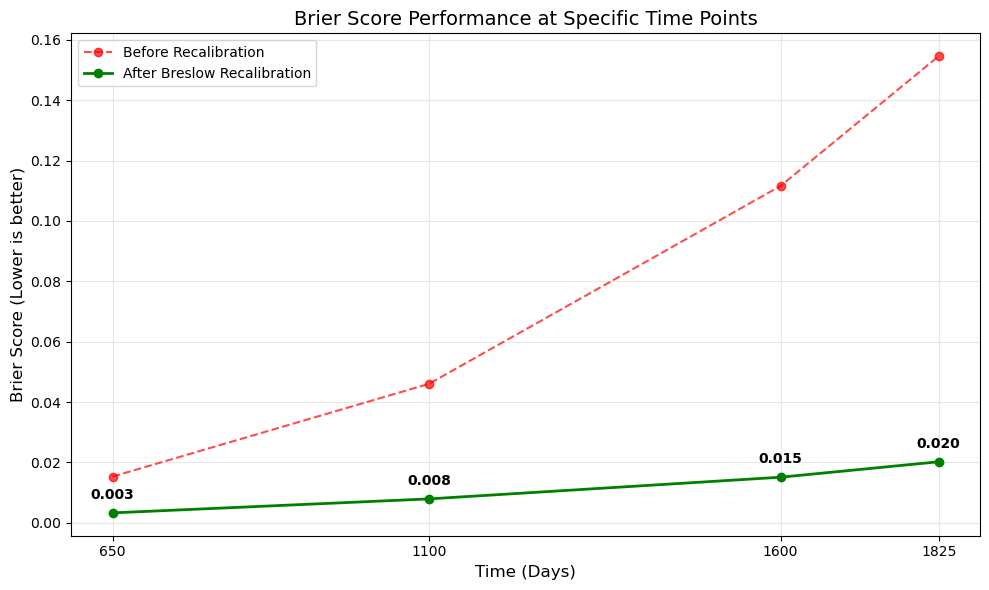

In [9]:
from sksurv.metrics import brier_score

# Time points of interest (must match time_points_eval used in previous cells)
target_times = [650, 1100, 1600, 1825]

print("="*70)
print("BRIER SCORE AT SPECIFIC TIME POINTS")
print("="*70)

try:
    # Calculate Brier score before recalibration
    # We use combined_y for both train and test to estimate censoring (IPCW) 
    # consistent with the notebook's previous IBS calculation
    _, bs_before = brier_score(
        combined_y, 
        combined_y, 
        combined_preds_before, 
        target_times
    )

    # Calculate Brier score after recalibration
    _, bs_after = brier_score(
        combined_y, 
        combined_y, 
        combined_preds_after, 
        target_times
    )

    # Create a summary DataFrame
    bs_df = pd.DataFrame({
        'Time Point (Days)': target_times,
        'Brier Score (Before)': bs_before,
        'Brier Score (After)': bs_after,
        'Improvement': bs_before - bs_after,
        'Improvement (%)': (bs_before - bs_after) / bs_before * 100
    })

    # Display table
    print(bs_df.to_string(index=False, float_format='%.4f'))

    # Optional: Visualization
    plt.figure(figsize=(10, 6))
    plt.plot(target_times, bs_before, 'o--', color='red', label='Before Recalibration', alpha=0.7)
    plt.plot(target_times, bs_after, 'o-', color='green', label='After Breslow Recalibration', linewidth=2)
    
    # Add annotations
    for i, txt in enumerate(bs_after):
        plt.annotate(f"{txt:.3f}", (target_times[i], bs_after[i]), 
                     textcoords="offset points", xytext=(0,10), ha='center', fontweight='bold')

    plt.xlabel('Time (Days)', fontsize=12)
    plt.ylabel('Brier Score (Lower is better)', fontsize=12)
    plt.title('Brier Score Performance at Specific Time Points', fontsize=14)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(target_times)
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Error calculating Brier scores: {e}")

preetty sure the above code is wrong I think it's using the tes set???

GAP ANALYSIS FOR RISK SCORE DISTRIBUTION

Basic Statistics:
  Min:    0.0000
  Max:    0.9744
  Mean:   0.0128
  Median: 0.0000
  Std:    0.0814

Percentile Analysis:
    0.00%: 0.0000
    5.00%: 0.0000
   10.00%: 0.0000
   20.00%: 0.0000
   25.00%: 0.0000
   30.00%: 0.0000
   33.33%: 0.0000
   40.00%: 0.0000
   50.00%: 0.0000
   60.00%: 0.0000
   66.67%: 0.0000
   70.00%: 0.0000
   75.00%: 0.0001
   80.00%: 0.0002
   90.00%: 0.0027
   95.00%: 0.0188
  100.00%: 0.9744

Top 5 Largest Gaps:
  Gap 1: Size=0.0731, Position=0.7198, Percentile≈99.5%
  Gap 2: Size=0.0495, Position=0.7942, Percentile≈99.6%
  Gap 3: Size=0.0447, Position=0.4172, Percentile≈98.8%
  Gap 4: Size=0.0370, Position=0.8762, Percentile≈99.7%
  Gap 5: Size=0.0367, Position=0.2997, Percentile≈98.5%

✓ Gap analysis plot saved to 'rsf_breslow_gap_analysis.png'


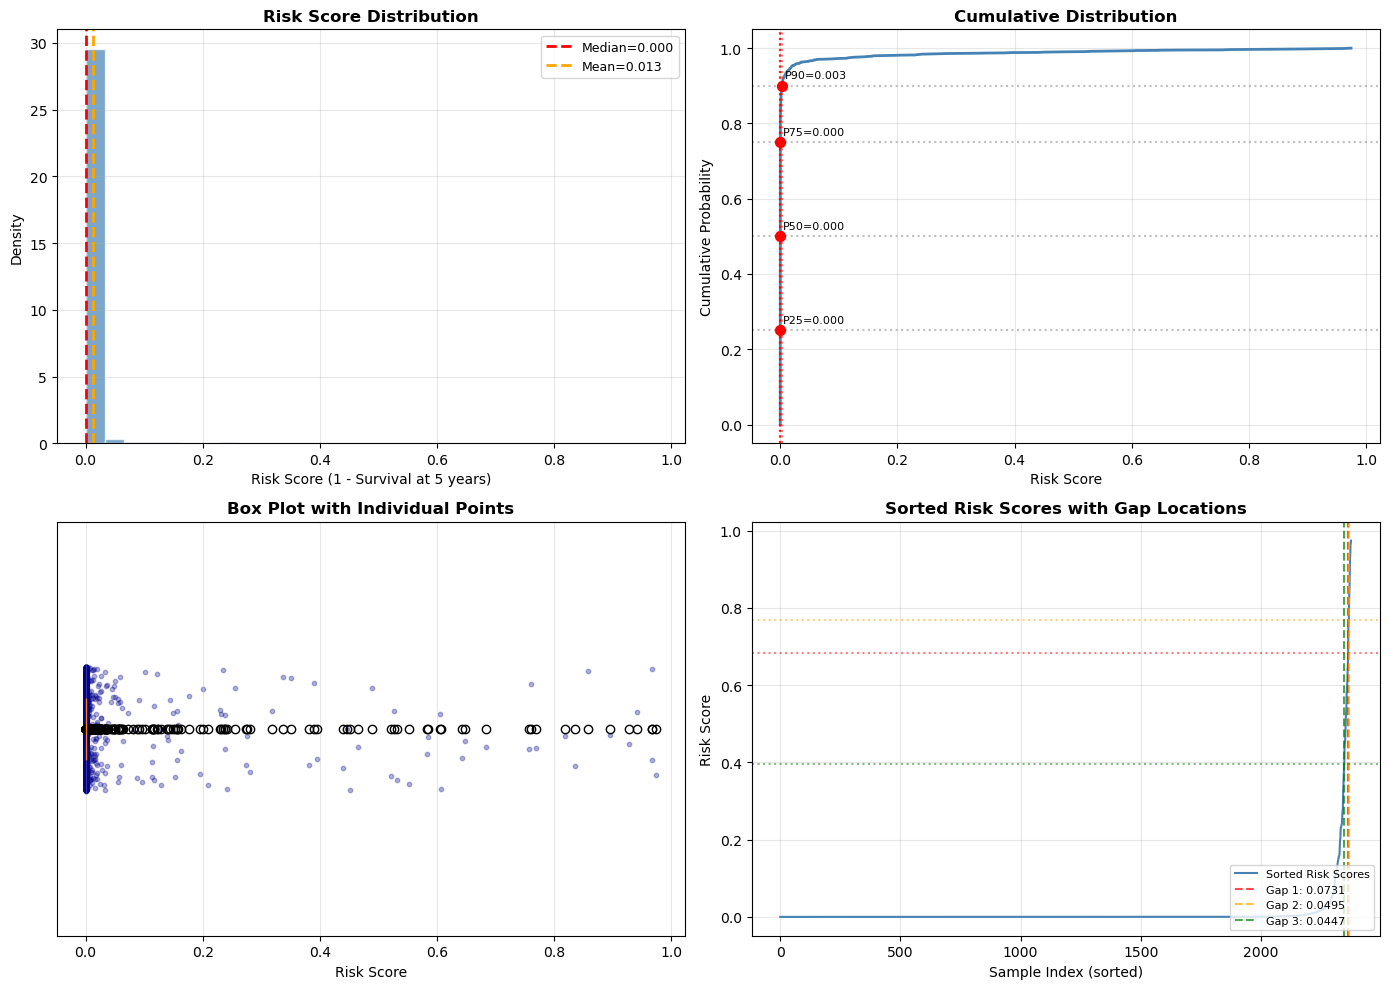


SUGGESTED BINNING STRATEGIES

1. Percentile-based (70/95):
   Low: 0 - 0.0000
   High: 0.0000 - 0.0188
   Very High: > 0.0188

2. Gap-based (natural breakpoints):
   Low: 0 - 0.7198
   Medium: 0.7198 - 0.7942
   High: > 0.7942


In [10]:
# ============================================
# GAP ANALYSIS FOR OPTIMAL BIN SPLITTING
# ============================================
# Use the risk scores (1 - survival at 5 years) to find natural breakpoints

# Get risk scores at 5-year time point (1825 days)
time_point_gap = 1825
time_idx_gap = time_points_eval.index(time_point_gap) if time_point_gap in time_points_eval else 1
risk_scores_gap = 1 - combined_preds_after[:, time_idx_gap]

print("="*70)
print("GAP ANALYSIS FOR RISK SCORE DISTRIBUTION")
print("="*70)

# Basic statistics
print(f"\nBasic Statistics:")
print(f"  Min:    {risk_scores_gap.min():.4f}")
print(f"  Max:    {risk_scores_gap.max():.4f}")
print(f"  Mean:   {risk_scores_gap.mean():.4f}")
print(f"  Median: {np.median(risk_scores_gap):.4f}")
print(f"  Std:    {risk_scores_gap.std():.4f}")

# Percentile analysis
percentiles_gap = [0, 5, 10, 20, 25, 30, 33.33, 40, 50, 60, 66.67, 70, 75, 80, 90, 95, 100]
print(f"\nPercentile Analysis:")
for p in percentiles_gap:
    val = np.percentile(risk_scores_gap, p)
    print(f"  {p:6.2f}%: {val:.4f}")

# Find natural gaps in the distribution
sorted_risks_gap = np.sort(risk_scores_gap)
gaps = np.diff(sorted_risks_gap)

# Find top 5 largest gaps
n_gaps = min(5, len(gaps))
large_gaps_idx = np.argsort(gaps)[-n_gaps:][::-1]  # Top 5 largest gaps

print(f"\nTop {n_gaps} Largest Gaps:")
for i, idx in enumerate(large_gaps_idx):
    gap_size = gaps[idx]
    position = (sorted_risks_gap[idx] + sorted_risks_gap[idx + 1]) / 2
    percentile_pos = (idx + 0.5) / len(sorted_risks_gap) * 100
    print(f"  Gap {i+1}: Size={gap_size:.4f}, Position={position:.4f}, Percentile≈{percentile_pos:.1f}%")

# Visualization - 4 panel plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Histogram with KDE
ax1 = axes[0, 0]
ax1.hist(risk_scores_gap, bins=30, density=True, alpha=0.7, color='steelblue', edgecolor='white')
ax1.set_xlabel('Risk Score (1 - Survival at 5 years)', fontsize=10)
ax1.set_ylabel('Density', fontsize=10)
ax1.set_title('Risk Score Distribution', fontsize=12, fontweight='bold')
ax1.axvline(np.median(risk_scores_gap), color='red', linestyle='--', linewidth=2, label=f'Median={np.median(risk_scores_gap):.3f}')
ax1.axvline(risk_scores_gap.mean(), color='orange', linestyle='--', linewidth=2, label=f'Mean={risk_scores_gap.mean():.3f}')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

# Panel 2: Cumulative distribution
ax2 = axes[0, 1]
sorted_data = np.sort(risk_scores_gap)
cumulative = np.arange(1, len(sorted_data) + 1) / len(sorted_data)
ax2.plot(sorted_data, cumulative, color='steelblue', linewidth=2)
ax2.set_xlabel('Risk Score', fontsize=10)
ax2.set_ylabel('Cumulative Probability', fontsize=10)
ax2.set_title('Cumulative Distribution', fontsize=12, fontweight='bold')
# Add percentile markers
for p in [25, 50, 75, 90]:
    val = np.percentile(risk_scores_gap, p)
    ax2.axhline(p/100, color='gray', linestyle=':', alpha=0.5)
    ax2.axvline(val, color='red', linestyle=':', alpha=0.5)
    ax2.scatter([val], [p/100], color='red', s=50, zorder=5)
    ax2.text(val + 0.005, p/100 + 0.02, f'P{p}={val:.3f}', fontsize=8)
ax2.grid(True, alpha=0.3)

# Panel 3: Box plot with individual points
ax3 = axes[1, 0]
bp = ax3.boxplot(risk_scores_gap, vert=False, patch_artist=True)
bp['boxes'][0].set_facecolor('steelblue')
bp['boxes'][0].set_alpha(0.7)
ax3.scatter(risk_scores_gap, np.ones(len(risk_scores_gap)) + (np.random.rand(len(risk_scores_gap)) - 0.5) * 0.3, 
            alpha=0.3, s=10, color='darkblue')
ax3.set_xlabel('Risk Score', fontsize=10)
ax3.set_title('Box Plot with Individual Points', fontsize=12, fontweight='bold')
ax3.set_yticks([])
ax3.grid(True, alpha=0.3, axis='x')

# Panel 4: Gap analysis visualization
ax4 = axes[1, 1]
ax4.plot(range(len(sorted_risks_gap)), sorted_risks_gap, color='steelblue', linewidth=1.5, label='Sorted Risk Scores')
# Highlight large gaps
for i, idx in enumerate(large_gaps_idx[:3]):  # Top 3 gaps
    ax4.axvline(idx, color=['red', 'orange', 'green'][i], linestyle='--', 
                alpha=0.7, label=f'Gap {i+1}: {gaps[idx]:.4f}')
    ax4.axhline(sorted_risks_gap[idx], color=['red', 'orange', 'green'][i], 
                linestyle=':', alpha=0.5)
ax4.set_xlabel('Sample Index (sorted)', fontsize=10)
ax4.set_ylabel('Risk Score', fontsize=10)
ax4.set_title('Sorted Risk Scores with Gap Locations', fontsize=12, fontweight='bold')
ax4.legend(fontsize=8, loc='lower right')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
#plt.savefig('rsf_breslow_gap_analysis.png', dpi=300, bbox_inches='tight')
print("\n✓ Gap analysis plot saved to 'rsf_breslow_gap_analysis.png'")
plt.show()

# Suggest optimal binning based on gaps
print(f"\n" + "="*70)
print("SUGGESTED BINNING STRATEGIES")
print("="*70)

# Strategy 1: Percentile-based (current)
print(f"\n1. Percentile-based (70/95):")
print(f"   Low: 0 - {np.percentile(risk_scores_gap, 70):.4f}")
print(f"   High: {np.percentile(risk_scores_gap, 70):.4f} - {np.percentile(risk_scores_gap, 95):.4f}")
print(f"   Very High: > {np.percentile(risk_scores_gap, 95):.4f}")

# Strategy 2: Gap-based (using top 2 gaps)
gap1_pos = (sorted_risks_gap[large_gaps_idx[0]] + sorted_risks_gap[large_gaps_idx[0] + 1]) / 2
if len(large_gaps_idx) > 1:
    gap2_pos = (sorted_risks_gap[large_gaps_idx[1]] + sorted_risks_gap[large_gaps_idx[1] + 1]) / 2
    cutoffs = sorted([gap1_pos, gap2_pos])
    print(f"\n2. Gap-based (natural breakpoints):")
    print(f"   Low: 0 - {cutoffs[0]:.4f}")
    print(f"   Medium: {cutoffs[0]:.4f} - {cutoffs[1]:.4f}")
    print(f"   High: > {cutoffs[1]:.4f}")

✓ Calibration plot saved!

Risk Categories:
  Low Risk: Bottom 33%
  High Risk: 33-66%
  Very High Risk: Top 34%


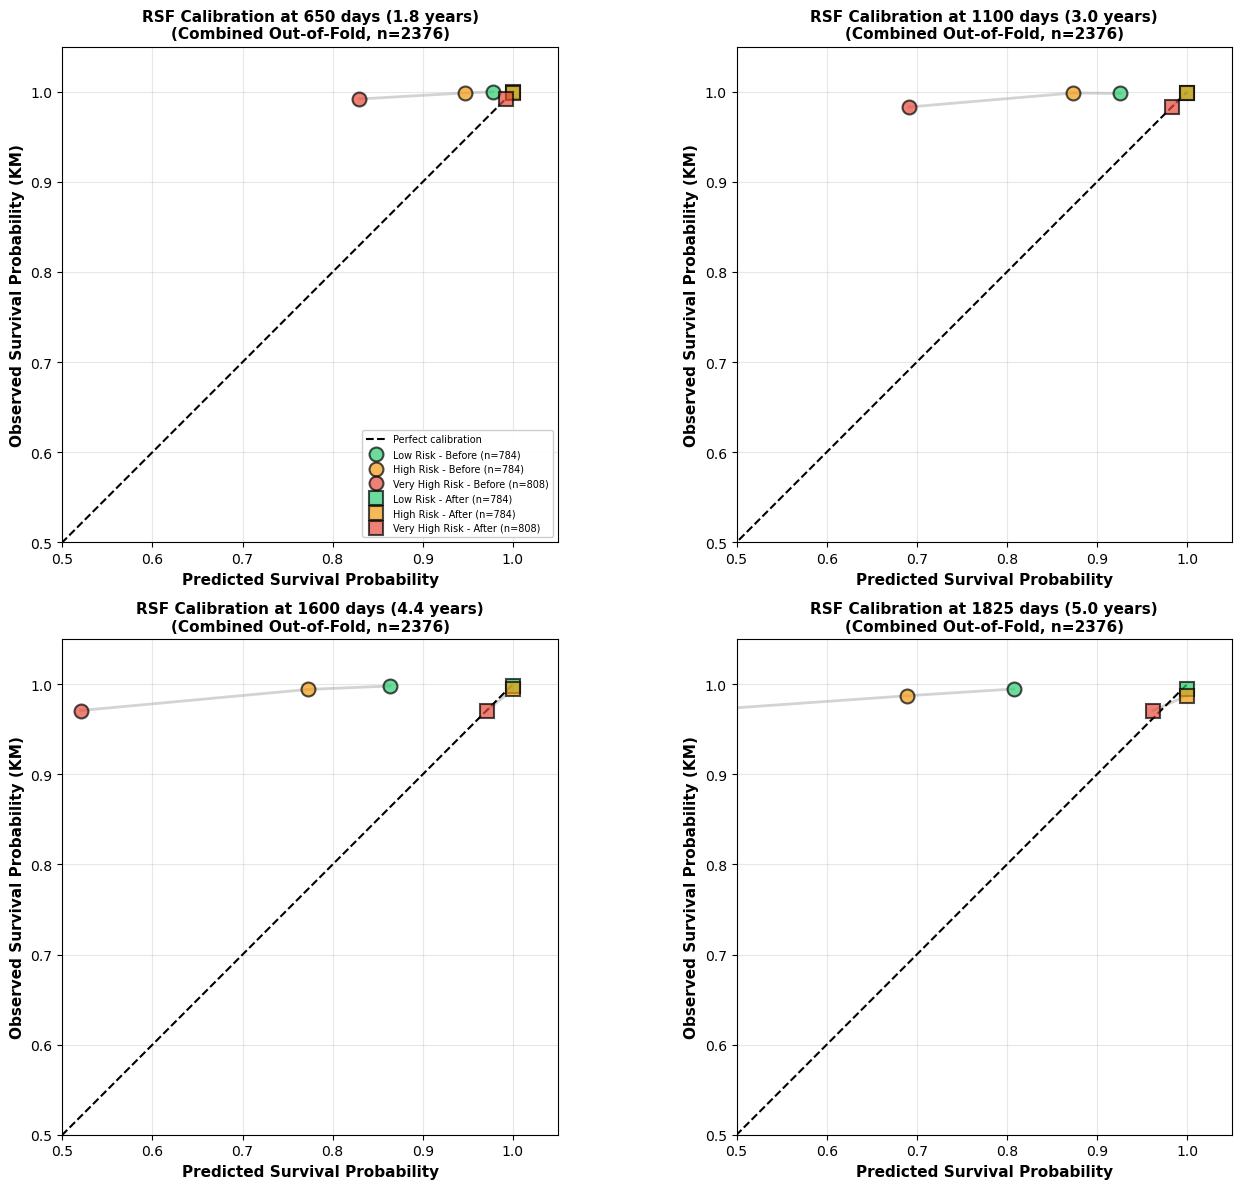


✓ Calibration data saved to 'rsf_breslow_calibration_data.csv'
  Columns: ['time_point', 'risk_bin', 'risk_category', 'mean_pred_before', 'mean_pred_after', 'mean_observed', 'mean_risk_pred_before', 'mean_risk_pred_after', 'mean_risk_observed', 'bin_size']


In [11]:
# CALIBRATION PLOT using combined out-of-fold predictions
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

# Risk bin definitions
percentile_thresholds = [33, 66]

for idx, time_point in enumerate(time_points_eval):
    ax = axes[idx]
    
    pred_surv_before = combined_preds_before[:, idx]
    pred_surv_after = combined_preds_after[:, idx]
    risk_scores = 1 - pred_surv_after
    
    # Create bins based on percentiles
    thresh_low = np.percentile(risk_scores, percentile_thresholds[0])
    thresh_high = np.percentile(risk_scores, percentile_thresholds[1])
    
    # Assign risk categories (3 bins)
    risk_labels = np.zeros(len(risk_scores), dtype=int)
    risk_labels[risk_scores > thresh_low] = 1   # High risk
    risk_labels[risk_scores > thresh_high] = 2  # Very high risk

    risk_names = ['Low Risk', 'High Risk', 'Very High Risk']
    colors_bins = ['#2ecc71', '#f39c12', '#e74c3c']  # Green, Orange, Red
    
    mean_pred_before = []
    mean_pred_after = []
    mean_observed = []
    bin_sizes = []
    
    for bin_idx in range(3):
        mask = risk_labels == bin_idx
        bin_sizes.append(mask.sum())
        
        if mask.sum() == 0:
            continue
        
        mean_pred_before.append(pred_surv_before[mask].mean())
        mean_pred_after.append(pred_surv_after[mask].mean())
        
        km_time, km_prob = kaplan_meier_estimator(
            combined_y['event'][mask],
            combined_y['time'][mask]
        )
        
        if time_point <= km_time.min():
            obs_surv = 1.0
        elif time_point >= km_time.max():
            obs_surv = km_prob[-1]
        else:
            obs_surv = np.interp(time_point, km_time, km_prob)
        
        mean_observed.append(obs_surv)
    
    # Plot
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration', linewidth=1.5)
    
    # Connecting lines
    ax.plot(mean_pred_before, mean_observed, '-', color='lightgray', linewidth=2, zorder=1)
    ax.plot(mean_pred_after, mean_observed, '-', color='lightgray', linewidth=2, zorder=1)
    
    # Markers - BEFORE calibration
    for i in range(len(mean_pred_before)):
        label_before = f'{risk_names[i]} - Before (n={bin_sizes[i]})' if idx == 0 else None
        ax.plot([mean_pred_before[i]], [mean_observed[i]], 'o',
                color=colors_bins[i], markersize=10, alpha=0.7,
                markeredgecolor='black', markeredgewidth=1.5,
                label=label_before, zorder=3)
    
    # Markers - AFTER calibration
    for i in range(len(mean_pred_after)):
        label_after = f'{risk_names[i]} - After (n={bin_sizes[i]})' if idx == 0 else None
        ax.plot([mean_pred_after[i]], [mean_observed[i]], 's',
                color=colors_bins[i], markersize=10, alpha=0.7,
                markeredgecolor='black', markeredgewidth=1.5,
                label=label_after, zorder=3)
    
    ax.set_xlabel('Predicted Survival Probability', fontsize=11, fontweight='bold')
    ax.set_ylabel('Observed Survival Probability (KM)', fontsize=11, fontweight='bold')
    ax.set_title(f'RSF Calibration at {time_point} days ({time_point/365:.1f} years)\n(Combined Out-of-Fold, n={len(combined_y)})', 
                 fontsize=11, fontweight='bold')
    if idx == 0:
        ax.legend(loc='lower right', fontsize=7, framealpha=0.95, ncol=1)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0.5, 1.05)
    ax.set_ylim(0.5, 1.05)
    ax.set_aspect('equal')

plt.tight_layout()
#plt.savefig('rsf_breslow_calibration_cv.png', dpi=300, bbox_inches='tight')
#plt.savefig('rsf_breslow_calibration_cv.pdf', dpi=300, bbox_inches='tight')
print("✓ Calibration plot saved!")
print(f"\nRisk Categories:")
print(f"  Low Risk: Bottom {percentile_thresholds[0]}%")
print(f"  High Risk: {percentile_thresholds[0]}-{percentile_thresholds[1]}%")
print(f"  Very High Risk: Top {100-percentile_thresholds[1]}%")
plt.show()

# ============================================
# Save calibration data to CSV
# ============================================
calibration_data = []

for idx, time_point in enumerate(time_points_eval):
    pred_surv_before = combined_preds_before[:, idx]
    pred_surv_after = combined_preds_after[:, idx]
    risk_scores = 1 - pred_surv_after
    
    # Create bins based on percentiles
    thresh_low = np.percentile(risk_scores, percentile_thresholds[0])
    thresh_high = np.percentile(risk_scores, percentile_thresholds[1])
    
    # Assign risk categories (3 bins)
    risk_labels = np.zeros(len(risk_scores), dtype=int)
    risk_labels[risk_scores > thresh_low] = 1
    risk_labels[risk_scores > thresh_high] = 2
    
    risk_names = ['Low Risk', 'High Risk', 'Very High Risk']
    
    for bin_idx in range(3):
        mask = risk_labels == bin_idx
        bin_size = mask.sum()
        
        if bin_size == 0:
            continue
        
        mean_pred_before = pred_surv_before[mask].mean()
        mean_pred_after = pred_surv_after[mask].mean()
        
        km_time, km_prob = kaplan_meier_estimator(
            combined_y['event'][mask],
            combined_y['time'][mask]
        )
        
        if time_point <= km_time.min():
            obs_surv = 1.0
        elif time_point >= km_time.max():
            obs_surv = km_prob[-1]
        else:
            obs_surv = np.interp(time_point, km_time, km_prob)
        
        calibration_data.append({
            'time_point': time_point,
            'risk_bin': bin_idx,
            'risk_category': risk_names[bin_idx],
            'mean_pred_before': mean_pred_before,
            'mean_pred_after': mean_pred_after,
            'mean_observed': obs_surv,
            'mean_risk_pred_before': 1 - mean_pred_before,
            'mean_risk_pred_after': 1 - mean_pred_after,
            'mean_risk_observed': 1 - obs_surv,
            'bin_size': bin_size
        })

# Save to CSV
calibration_df = pd.DataFrame(calibration_data)
# calibration_df.to_csv('rsf_breslow_calibration_data.csv', index=False)
print(f"\n✓ Calibration data saved to 'rsf_breslow_calibration_data.csv'")
print(f"  Columns: {list(calibration_df.columns)}")

Timepoint  | Slope      | Intercept  | AUC       
--------------------------------------------------
650        | 0.367      | -1.864     | 0.847     


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\statsmodels\nonparametric\smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),


1100       | 0.324      | -1.622     | 0.853     


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\statsmodels\nonparametric\smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),


1600       | 0.279      | -1.283     | 0.831     
1825       | 0.227      | -1.483     | 0.781     


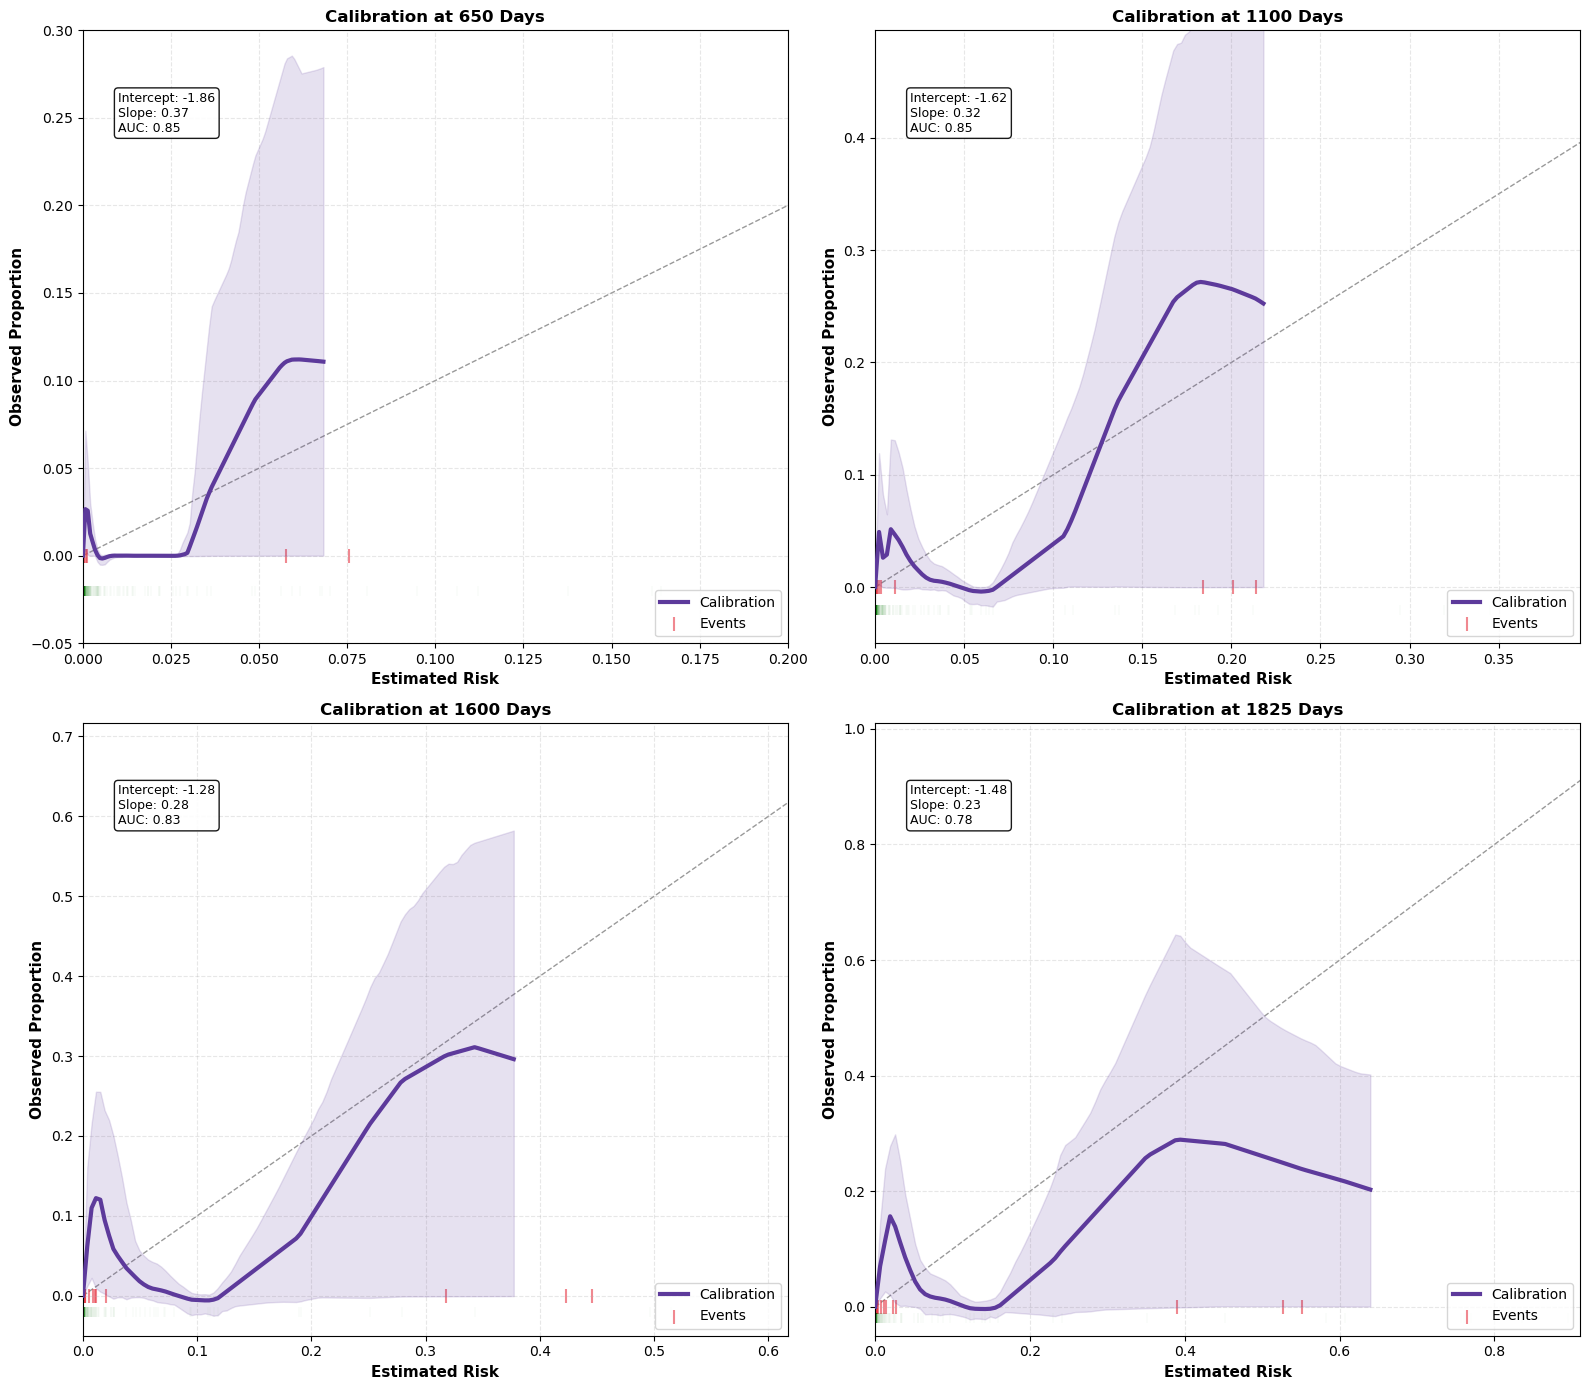

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.utils import resample
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy.special import expit, logit

# ============================================
# HELPER: Bootstrap with Safety Checks
# ============================================
def bootstrap_calibration_safe(y_true, y_pred, n_boot=100, smooth_frac=0.4):
    """
    Robust bootstrap that handles sparse tails.
    """
    # Define grid only up to the max prediction to avoid "crashing" the curve
    max_val = np.percentile(y_pred, 99) * 1.2
    if max_val > 1.0: max_val = 1.0
    x_grid = np.linspace(0, max_val, 100)
    
    boot_predictions = []
    
    for i in range(n_boot):
        # Resample
        y_t_boot, y_p_boot = resample(y_true, y_pred, random_state=i)
        
        # Fit LOESS
        # We catch warnings to keep the output clean
        try:
            smoothed = lowess(y_t_boot, y_p_boot, frac=smooth_frac, it=0, return_sorted=True)
            
            # Interpolate safely
            # We assume the curve is flat (linear) past the last data point
            boot_line = np.interp(x_grid, smoothed[:, 0], smoothed[:, 1], left=0, right=smoothed[-1, 1])
            boot_predictions.append(boot_line)
        except:
            continue
            
    if len(boot_predictions) == 0:
        return x_grid, x_grid, x_grid, x_grid # Fail gracefully
        
    boot_predictions = np.array(boot_predictions)
    
    # 95% CI
    ci_lower = np.percentile(boot_predictions, 2.5, axis=0)
    ci_upper = np.percentile(boot_predictions, 97.5, axis=0)
    mean_curve = np.mean(boot_predictions, axis=0)
    
    return x_grid, mean_curve, ci_lower, ci_upper

# ============================================
# MAIN PLOTTING LOOP
# ============================================
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.ravel()

print(f"{'Timepoint':<10} | {'Slope':<10} | {'Intercept':<10} | {'AUC':<10}")
print("-" * 50)

for idx, time_point in enumerate(time_points_eval):
    if idx >= len(axes): break
    ax = axes[idx]
    
    # 1. Prepare Data
    # -------------------------------------------------------
    valid_mask = ~((combined_y['event'] == 0) & (combined_y['time'] < time_point))
    
    y_true = ((combined_y['time'][valid_mask] <= time_point) & (combined_y['event'][valid_mask] == 1)).astype(int)
    y_pred = 1 - combined_preds_after[valid_mask, idx]
    
    # Safety: Clip 0 and 1 to prevent log(0) errors (The cause of "Metrics Error")
    y_pred = np.clip(y_pred, 1e-6, 1 - 1e-6)

    # 2. Calculate Metrics (Robust Method)
    # -------------------------------------------------------
    try:
        # Calculate Log-Odds (Logit)
        log_odds = logit(y_pred).reshape(-1, 1)
        
        # Fit Logistic Regression (Sklearn is more stable than Statsmodels here)
        clf = LogisticRegression(C=1e9, solver='lbfgs') # C=large means no regularization (pure fit)
        clf.fit(log_odds, y_true)
        
        slope = clf.coef_[0][0]
        intercept = clf.intercept_[0]
        
        auc = roc_auc_score(y_true, y_pred)
        
        # Text for the plot
        stats_text = (f"Intercept: {intercept:.2f}\n"
                      f"Slope: {slope:.2f}\n"
                      f"AUC: {auc:.2f}")
        
        print(f"{time_point:<10} | {slope:<10.3f} | {intercept:<10.3f} | {auc:<10.3f}")
        
    except Exception as e:
        print(f"Metrics failed at {time_point}: {e}")
        stats_text = "Metrics Error\n(Data too sparse)"

    # 3. Generate Curve
    # -------------------------------------------------------
    # We increase 'frac' slightly (0.5) to make the curve smoother and less jittery
    x_grid, mean_curve, ci_lower, ci_upper = bootstrap_calibration_safe(y_true, y_pred, n_boot=100, smooth_frac=0.5)

    # 4. Plotting
    # -------------------------------------------------------
    
    # A. Perfect Line
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.4, zorder=1)
    
    # B. Smooth Curve & CI
    ax.plot(x_grid, mean_curve, color='#5D3A9B', linewidth=3, zorder=3, label='Calibration')
    ax.fill_between(x_grid, ci_lower, ci_upper, color='#5D3A9B', alpha=0.15, zorder=2)
    
    # C. Rug Plot (Survivors vs Events)
    # We separate them to see where the risks actually land
    
    # Events (Top red ticks)
    events_risk = y_pred[y_true == 1]
    ax.scatter(events_risk, np.ones_like(events_risk) * 0.0, 
               marker='|', color='#E63946', alpha=0.6, s=100, label='Events')
               
    # Survivors (Bottom green ticks, very transparent)
    surv_risk = y_pred[y_true == 0]
    ax.scatter(surv_risk, np.zeros_like(surv_risk) - 0.02, 
               marker='|', color='green', alpha=0.02, s=50)

    # 5. Formatting
    # -------------------------------------------------------
    # AUTO-ZOOM: Determine the max x-limit based on data
    # If your max risk is 0.25, show up to 0.3. Don't show empty space up to 1.0
    max_disp = np.percentile(y_pred, 99.5)
    max_disp = min(max_disp * 1.2, 1.0) # Add 20% buffer, cap at 1.0
    if max_disp < 0.2: max_disp = 0.2 # Minimum width
    
    ax.set_xlim(0, max_disp)
    ax.set_ylim(-0.05, max_disp + 0.1) # Scale Y similarly to X for aspect ratio
    
    ax.set_xlabel('Estimated Risk', fontsize=11, fontweight='bold')
    ax.set_ylabel('Observed Proportion', fontsize=11, fontweight='bold')
    
    # Add stats box
    ax.text(0.05, 0.9, stats_text, transform=ax.transAxes, fontsize=9, 
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))

    ax.set_title(f'Calibration at {time_point} Days', fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.legend(loc='lower right')

plt.tight_layout()
# plt.savefig('final_calibration_zoomed.png', dpi=300)
plt.show()

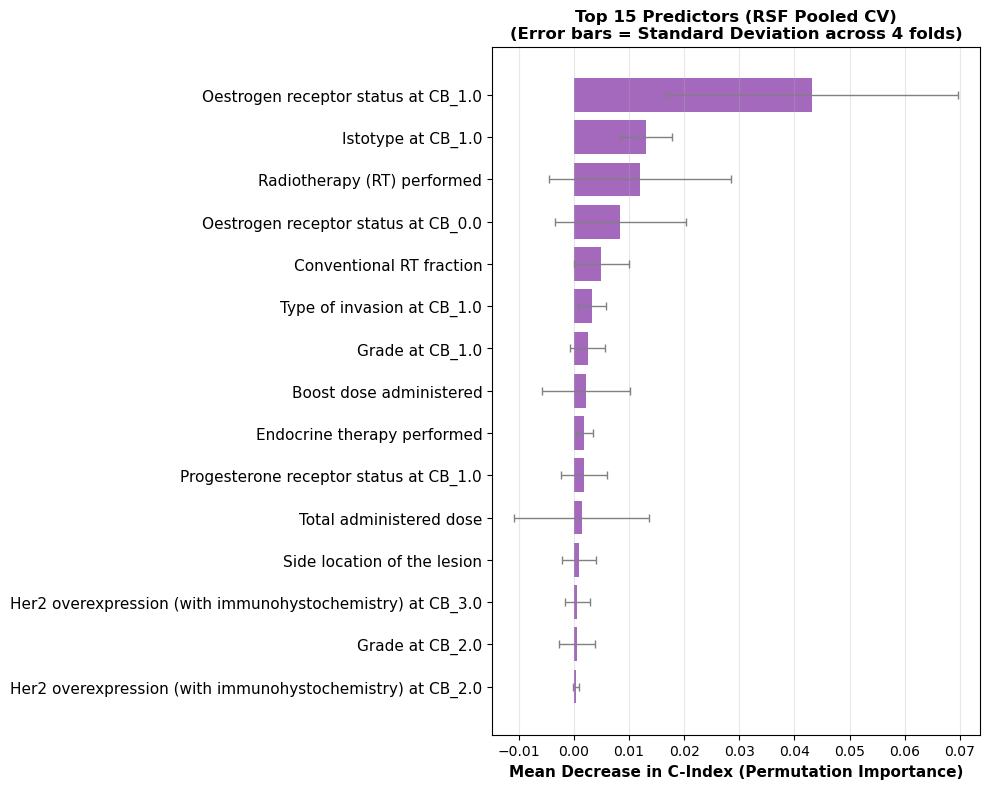

✓ Permutation importance plot saved.

Top 5 Features:
                            Feature  Importance  Importance_Std
Oestrogen receptor status at CB_1.0    0.043200        0.026417
                 Istotype at CB_1.0    0.013137        0.004724
        Radiotherapy (RT) performed    0.011979        0.016483
Oestrogen receptor status at CB_0.0    0.008410        0.011852
           Conventional RT fraction    0.004992        0.004987


In [13]:
# ============================================
# RSF FEATURE IMPORTANCE (POOLED PERMUTATION IMPORTANCE)
# ============================================
import pandas as pd
import matplotlib.pyplot as plt

# 1. Aggregate results from the list
# Shape: (n_folds, n_features)
perm_importances_array = np.array(all_fold_feature_importances)

# Calculate Mean and Std across folds
mean_perm_importance = np.mean(perm_importances_array, axis=0)
std_perm_importance = np.std(perm_importances_array, axis=0)

# 2. Create DataFrame
feature_names = x_train_sub.columns
feature_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': mean_perm_importance,
    'Importance_Std': std_perm_importance
})

# 3. Sort and Select Top N
top_n = 15
feature_df = feature_df.sort_values(by='Importance', ascending=False)
top_features = feature_df.head(top_n)

# 4. Plot
fig, ax = plt.subplots(figsize=(10, 8))

# Create horizontal bars with ERROR BARS (xerr)
bars = ax.barh(range(top_n), top_features['Importance'], 
               xerr=top_features['Importance_Std'], 
               align='center', 
               color='#8e44ad', alpha=0.8, 
               capsize=3, 
               error_kw={'linewidth': 1, 'ecolor': 'gray'})

ax.set_yticks(range(top_n))
ax.set_yticklabels(top_features['Feature'], fontsize=11)
ax.invert_yaxis()  # Highest importance at the top

# Labels and Title
ax.set_xlabel('Mean Decrease in C-Index (Permutation Importance)', fontsize=11, fontweight='bold')
ax.set_title(f'Top {top_n} Predictors (RSF Pooled CV)\n(Error bars = Standard Deviation across {len(all_fold_feature_importances)} folds)', 
             fontsize=12, fontweight='bold')

ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
# plt.savefig('rsf_permutation_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Permutation importance plot saved.")
print("\nTop 5 Features:")
print(top_features[['Feature', 'Importance', 'Importance_Std']].head(5).to_string(index=False))

# feature_df.to_csv("../../../results/features/rsf_feature_importance.csv", index=False)

In [14]:
# ============================================
# SURVSHAP SETUP AND IMPORTS
# ============================================
# Add survshap package to path (use insert to prioritize local package)
sys.path.insert(0, os.path.abspath('../../../survshap-main/survshap_package'))

from survshap import SurvivalModelExplainer, ModelSurvSHAP, PredictSurvSHAP
from tqdm import tqdm

print("="*70)
print("SURVSHAP ANALYSIS FOR RANDOM SURVIVAL FOREST")
print("="*70)
print("SurvSHAP(t) provides time-dependent SHAP values for survival models")
print("This shows how each feature contributes to the survival prediction at each time point")

SURVSHAP ANALYSIS FOR RANDOM SURVIVAL FOREST
SurvSHAP(t) provides time-dependent SHAP values for survival models
This shows how each feature contributes to the survival prediction at each time point


In [15]:
# ============================================
# TRAIN FINAL RSF MODEL ON FULL TRAINING POOL FOR SHAP ANALYSIS
# ============================================
# We train a final model on the full training pool (without CV split) for SHAP analysis

print("Training final RSF model on full training pool for SHAP analysis...")

# Apply case-control subsampling to full training pool
x_train_shap, y_train_shap, train_shap_df = sample_case_control(
    train_fold=train_pool_dataset,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_controls_per_case=int(best_params['n_controls_per_case']),
    feature_columns=feature_columns,
    random_state=12
)

print(f"  Full training pool: {len(x_train_pool)} samples")
print(f"  Subsampled for training: {len(x_train_shap)} samples")
print(f"  Events in subsampled data: {y_train_shap['event'].sum()}")

# Train final RSF model (no scaling needed for tree-based models)
rsf_model_shap = RandomSurvivalForest(
    n_estimators=int(best_params['n_estimators']),
    max_depth=max_depth,
    max_features=max_features,
    min_samples_leaf=int(best_params['min_samples_leaf']),
    random_state=12,
    n_jobs=-1
)
rsf_model_shap.fit(x_train_shap, y_train_shap)

print(f"\n✓ Final RSF model trained for SHAP analysis")
print(f"  C-index on training data: {rsf_model_shap.score(x_train_shap, y_train_shap):.4f}")

Training final RSF model on full training pool for SHAP analysis...
  Full training pool: 2376 samples
  Subsampled for training: 54 samples
  Events in subsampled data: 27

✓ Final RSF model trained for SHAP analysis
  C-index on training data: 0.8763


In [33]:
# ============================================
# BRESLOW RECALIBRATION FOR SHAP MODEL
# ============================================
# Apply Breslow baseline hazard estimation using the FULL (non-subsampled) training pool
# This ensures the SHAP survival curves are recalibrated consistently with the CV evaluation

print("="*70)
print("BRESLOW RECALIBRATION FOR SHAP MODEL")
print("="*70)

# Get risk scores on FULL (non-subsampled) training pool
train_risk_scores_shap = rsf_model_shap.predict(x_train_pool)
risk_scores_train_shap = np.exp(train_risk_scores_shap)

# Breslow baseline hazard estimation using full training pool data
survival_times_shap = y_train_pool['time']
events_shap = y_train_pool['event']
unique_times_shap = np.sort(np.unique(survival_times_shap[events_shap == 1]))
baseline_hazard_shap = []

for t in unique_times_shap:
    d_t = np.sum((survival_times_shap == t) & (events_shap == 1))
    at_risk = survival_times_shap >= t
    risk_sum = np.sum(risk_scores_train_shap[at_risk])
    h_0_t = d_t / risk_sum if risk_sum > 0 else 0
    baseline_hazard_shap.append(h_0_t)

baseline_hazard_df_shap = pd.DataFrame({
    'timeline': unique_times_shap,
    'baseline_hazard': baseline_hazard_shap
})
baseline_hazard_df_shap['baseline_cumulative_hazard'] = np.cumsum(baseline_hazard_df_shap['baseline_hazard'])

print(f"  Training pool size (full, non-subsampled): {len(x_train_pool)}")
print(f"  Events in training pool: {events_shap.sum()}")
print(f"  Unique event times: {len(unique_times_shap)}")
print(f"  Baseline hazard range: [{baseline_hazard_df_shap['baseline_cumulative_hazard'].min():.4f}, {baseline_hazard_df_shap['baseline_cumulative_hazard'].max():.4f}]")


def compute_recalibrated_survival(risk_score, times, baseline_hazard_df_shap):
    """
    Compute recalibrated survival probabilities using Breslow baseline hazard.
    
    S(t|x) = exp(-H_0(t) * exp(risk_score))
    
    Parameters:
    -----------
    risk_score : float
        Linear predictor (risk score) from the model
    times : array-like
        Time points at which to compute survival probability
    baseline_hazard_df_shap : DataFrame
        DataFrame with 'timeline' and 'baseline_cumulative_hazard' columns
    
    Returns:
    --------
    survival_probs : array
        Survival probabilities at each time point
    """
    risk_ratio = np.exp(risk_score)
    survival_probs = np.zeros(len(times))
    
    for i, t in enumerate(times):
        if t <= baseline_hazard_df_shap['timeline'].min():
            cum_baseline_hazard = 0
        elif t >= baseline_hazard_df_shap['timeline'].max():
            cum_baseline_hazard = baseline_hazard_df_shap['baseline_cumulative_hazard'].iloc[-1]
        else:
            cum_baseline_hazard = np.interp(t, 
                                           baseline_hazard_df_shap['timeline'], 
                                           baseline_hazard_df_shap['baseline_cumulative_hazard'])
        survival_probs[i] = np.exp(-cum_baseline_hazard * risk_ratio)
    
    return survival_probs

print("\n✓ Breslow recalibration complete for SHAP model")
print("  Use compute_recalibrated_survival() for recalibrated survival curves")

BRESLOW RECALIBRATION FOR SHAP MODEL
  Training pool size (full, non-subsampled): 2376
  Events in training pool: 27
  Unique event times: 27
  Baseline hazard range: [0.0000, 0.0000]

✓ Breslow recalibration complete for SHAP model
  Use compute_recalibrated_survival() for recalibrated survival curves


In [16]:
# ============================================
# CREATE SURVSHAP EXPLAINER
# ============================================
# SurvivalModelExplainer wraps the model with background data for SHAP calculations
# We use a sample of the training data as background (100 samples for speed)

# Sample background data for SHAP (using stratified sampling to maintain event ratio)
np.random.seed(42)
n_background = min(100, len(x_train_shap))

# Stratified sampling for background data
events_idx = np.where(y_train_shap['event'] == 1)[0]
non_events_idx = np.where(y_train_shap['event'] == 0)[0]

# Maintain event ratio in background sample
n_events_bg = int(n_background * (len(events_idx) / len(y_train_shap)))
n_non_events_bg = n_background - n_events_bg

bg_events_idx = np.random.choice(events_idx, size=min(n_events_bg, len(events_idx)), replace=False)
bg_non_events_idx = np.random.choice(non_events_idx, size=min(n_non_events_bg, len(non_events_idx)), replace=False)
background_idx = np.concatenate([bg_events_idx, bg_non_events_idx])

background_data = x_train_shap.iloc[background_idx].reset_index(drop=True)
background_y = y_train_shap[background_idx]

print(f"Background data for SHAP: {len(background_data)} samples")
print(f"  Events in background: {background_y['event'].sum()}")
print(f"  Non-events in background: {(~background_y['event']).sum()}")

# Create the SurvivalModelExplainer
rsf_explainer = SurvivalModelExplainer(
    model=rsf_model_shap,
    data=background_data,
    y=background_y
)

print("\n✓ SurvivalModelExplainer created successfully")

Background data for SHAP: 54 samples
  Events in background: 27
  Non-events in background: 27

✓ SurvivalModelExplainer created successfully


In [24]:
# ============================================
# GLOBAL SURVSHAP ANALYSIS (ModelSurvSHAP)
# ============================================
# Calculate SHAP values for all observations and aggregate for global feature importance
# Using sampling method for compatibility with newer SHAP library versions

print("="*70)
print("GLOBAL SURVSHAP ANALYSIS")
print("="*70)
print("Calculating SurvSHAP(t) values for all training observations...")
print("Using Sampling method for Random Survival Forest")
print()

# Calculate time points for predictions
event_times = y_train_shap['time'][y_train_shap['event'] == 1]
timestamps = np.percentile(event_times, np.linspace(5, 95, 50))

# Use sampling method for RSF (compatible with newer SHAP versions)
global_survshap = ModelSurvSHAP(
    function_type="sf",  # Survival function
    calculation_method="sampling",  # Sampling method for compatibility
    aggregation_method="integral",  # Aggregate over time using integral
    random_state=42
)

# Fit on background data
global_survshap.fit(
    rsf_explainer,
    new_observations=background_data,  # Calculate SHAP for these observations
    timestamps=timestamps,  # Use defined timestamps
    save_individual_explanations=True  # Save individual explanations for later analysisprint("\n✓ Global SurvSHAP analysis completed!")

)

GLOBAL SURVSHAP ANALYSIS
Calculating SurvSHAP(t) values for all training observations...
Using Sampling method for Random Survival Forest



100%|██████████| 54/54 [55:05<00:00, 61.22s/it]


In [26]:
# ============================================
# DISPLAY GLOBAL SURVSHAP RESULTS
# ============================================
# Show aggregated feature importance from SurvSHAP

print("="*70)
print("GLOBAL FEATURE IMPORTANCE (Mean |SHAP| across time)")
print("="*70)

# Get the aggregated results
global_results = global_survshap.result.copy()
print(f"\nTop 15 Features by Mean Absolute SurvSHAP(t):")
print("-" * 60)
print(f"{'Feature':<40} {'Aggregated Change':>15}")
print("-" * 60)

for idx, row in global_results.head(15).iterrows():
    print(f"{row['variable_name']:<40} {row['aggregated_change']:>15.6f}")

# Save to CSV
global_results.to_csv('rsf_survshap_global_importance.csv', index=False)
print(f"\n✓ Global SurvSHAP results saved to 'rsf_survshap_global_importance.csv'")

GLOBAL FEATURE IMPORTANCE (Mean |SHAP| across time)


NameError: name 'global_survshap' is not defined

NameError: name 'global_results' is not defined

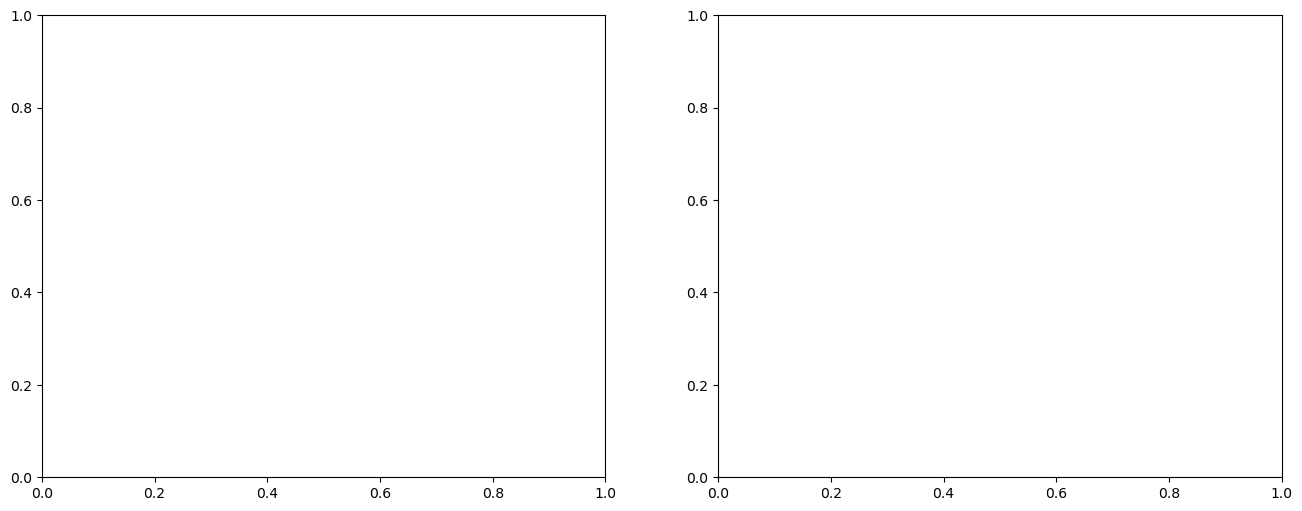

In [24]:
# ============================================
# PLOT GLOBAL SURVSHAP - MEAN ABSOLUTE SHAP VALUES OVER TIME
# ============================================
# Visualize how feature importance changes over time

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Bar plot of aggregated importance
ax1 = axes[0]
top_n = min(15, len(global_results))
top_features = global_results.head(top_n)

colors = plt.cm.viridis(np.linspace(0.2, 0.8, top_n))
bars = ax1.barh(range(top_n), top_features['aggregated_change'], color=colors)
ax1.set_yticks(range(top_n))
ax1.set_yticklabels(top_features['variable_name'], fontsize=9)
ax1.invert_yaxis()
ax1.set_xlabel('Aggregated |SHAP| (Integral over time)', fontsize=11, fontweight='bold')
ax1.set_title('RSF Global Feature Importance\n(Mean Absolute SurvSHAP)', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='x')

# Panel 2: SHAP values over time for top features
ax2 = axes[1]
timestamps = global_survshap.timestamps

# Get top 5 features for time-dependent plot
top_5_features = global_results['variable_name'].head(5).tolist()

# Extract SHAP values over time from full_result
full_result = global_survshap.full_result
time_cols = [col for col in full_result.columns if col.startswith('t = ')]

for i, feature in enumerate(top_5_features):
    # Get mean absolute SHAP values for this feature across all observations
    feature_data = full_result[full_result['variable_name'] == feature]
    feature_data_b0 = feature_data[feature_data['B'] == 0]  # Use averaged path (B=0)
    
    if len(feature_data_b0) > 0:
        mean_abs_shap = feature_data_b0[time_cols].abs().mean().values
        # Handle dimension mismatch between timestamps and SHAP values
        n_points = min(len(timestamps), len(mean_abs_shap))
        ax2.plot(timestamps[:n_points], mean_abs_shap[:n_points], linewidth=2, label=feature)

ax2.set_xlabel('Time (days)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Mean |SHAP|', fontsize=11, fontweight='bold')
ax2.set_title('RSF Feature Importance Over Time\n(Top 5 Features)', fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', fontsize=8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('rsf_survshap_global.png', dpi=300, bbox_inches='tight')

print("✓ Global SurvSHAP plot saved to 'rsf_survshap_global.png'")
plt.show()

In [28]:
# ============================================
# INDIVIDUAL SURVSHAP ANALYSIS (PredictSurvSHAP)
# ============================================
# Calculate SHAP values for specific individual predictions
# This helps understand why a specific patient has a particular risk profile
# 
# NOTE: Using "sampling" method - TreeSHAP has compatibility issues with newer SHAP versions

print("="*70)
print("INDIVIDUAL SURVSHAP ANALYSIS")
print("="*70)

# Get risk predictions on background/training data (for demonstration only)
risk_scores_background = rsf_model_shap.predict(background_data)

# Find high and low risk patients
high_risk_idx = np.argmax(risk_scores_background)
low_risk_idx = np.argmin(risk_scores_background)

print(f"High-risk patient index: {high_risk_idx} (risk score: {risk_scores_background[high_risk_idx]:.4f})")
print(f"Low-risk patient index: {low_risk_idx} (risk score: {risk_scores_background[low_risk_idx]:.4f})")

# Calculate individual SurvSHAP for high-risk patient
print(f"\nCalculating SurvSHAP for high-risk patient...")
high_risk_obs = background_data.iloc[[high_risk_idx]].reset_index(drop=True)

survshap_high_risk = PredictSurvSHAP(
    function_type="sf",
    calculation_method="sampling",  # Using sampling - more reliable than treeshap
    aggregation_method="integral"
)
survshap_high_risk.fit(rsf_explainer, high_risk_obs, timestamps=timestamps)

# Calculate individual SurvSHAP for low-risk patient
print(f"Calculating SurvSHAP for low-risk patient...")
low_risk_obs = background_data.iloc[[low_risk_idx]].reset_index(drop=True)

survshap_low_risk = PredictSurvSHAP(
    function_type="sf",
    calculation_method="sampling",  # Using sampling - more reliable than treeshap
    aggregation_method="integral"
)
survshap_low_risk.fit(rsf_explainer, low_risk_obs, timestamps=timestamps)

print("\n✓ Individual SurvSHAP calculations completed!")

INDIVIDUAL SURVSHAP ANALYSIS
High-risk patient index: 24 (risk score: 27.5721)
Low-risk patient index: 35 (risk score: 2.6270)

Calculating SurvSHAP for high-risk patient...


100%|██████████| 25/25 [00:50<00:00,  2.01s/it]


Calculating SurvSHAP for low-risk patient...


100%|██████████| 25/25 [00:41<00:00,  1.66s/it]


✓ Individual SurvSHAP calculations completed!


In [29]:
# ============================================
# DISPLAY INDIVIDUAL SURVSHAP RESULTS
# ============================================

print("="*70)
print("HIGH-RISK PATIENT SHAP CONTRIBUTIONS")
print("="*70)

# Get simplified results for high-risk patient
high_risk_simplified = survshap_high_risk.simplified_result.copy()
high_risk_simplified = high_risk_simplified.sort_values('aggregated_change', ascending=False, key=abs)

print(f"\nTop contributing features (positive = increases survival, negative = decreases survival):")
print("-" * 70)
print(f"{'Feature':<40} {'Variable Value':>12} {'SHAP Value':>12}")
print("-" * 70)

for idx, row in high_risk_simplified.head(10).iterrows():
    print(f"{row['variable_name']:<40} {row['variable_value']:>12.4f} {row['aggregated_change']:>12.6f}")

print("\n" + "="*70)
print("LOW-RISK PATIENT SHAP CONTRIBUTIONS")
print("="*70)

# Get simplified results for low-risk patient
low_risk_simplified = survshap_low_risk.simplified_result.copy()
low_risk_simplified = low_risk_simplified.sort_values('aggregated_change', ascending=False, key=abs)

survshap_high_risk.result.to_csv('rsf_survshap_high_risk_full.csv', index=False)
survshap_low_risk.result.to_csv('rsf_survshap_low_risk_full.csv', index=False)

print(f"\nTop contributing features (positive = increases survival, negative = decreases survival):")
print("-" * 70)
print(f"{'Feature':<40} {'Variable Value':>12} {'SHAP Value':>12}")
print("-" * 70)

for idx, row in low_risk_simplified.head(10).iterrows():
    print(f"{row['variable_name']:<40} {row['variable_value']:>12.4f} {row['aggregated_change']:>12.6f}")

HIGH-RISK PATIENT SHAP CONTRIBUTIONS

Top contributing features (positive = increases survival, negative = decreases survival):
----------------------------------------------------------------------
Feature                                  Variable Value   SHAP Value
----------------------------------------------------------------------
Oestrogen receptor status at CB_1.0            0.0000   169.930877
Grade at CB_3.0                                1.0000   130.850185
Radiotherapy (RT) performed                    0.0000   113.464840
Ki67 positive cells (%) at CB                 60.0000    99.307092
State (if hormone therapy prescribed)          0.0000    85.118626
Oestrogen receptor status at CB_0.0            1.0000    58.020601
Grade at CB_2.0                                0.0000    44.279178
Total administered dose                        0.0000    43.260146
Conventional RT fraction                       0.0000    37.771946
Source of referral                             1.0000    3

✓ Individual SurvSHAP plot saved to 'rsf_survshap_individual.png'


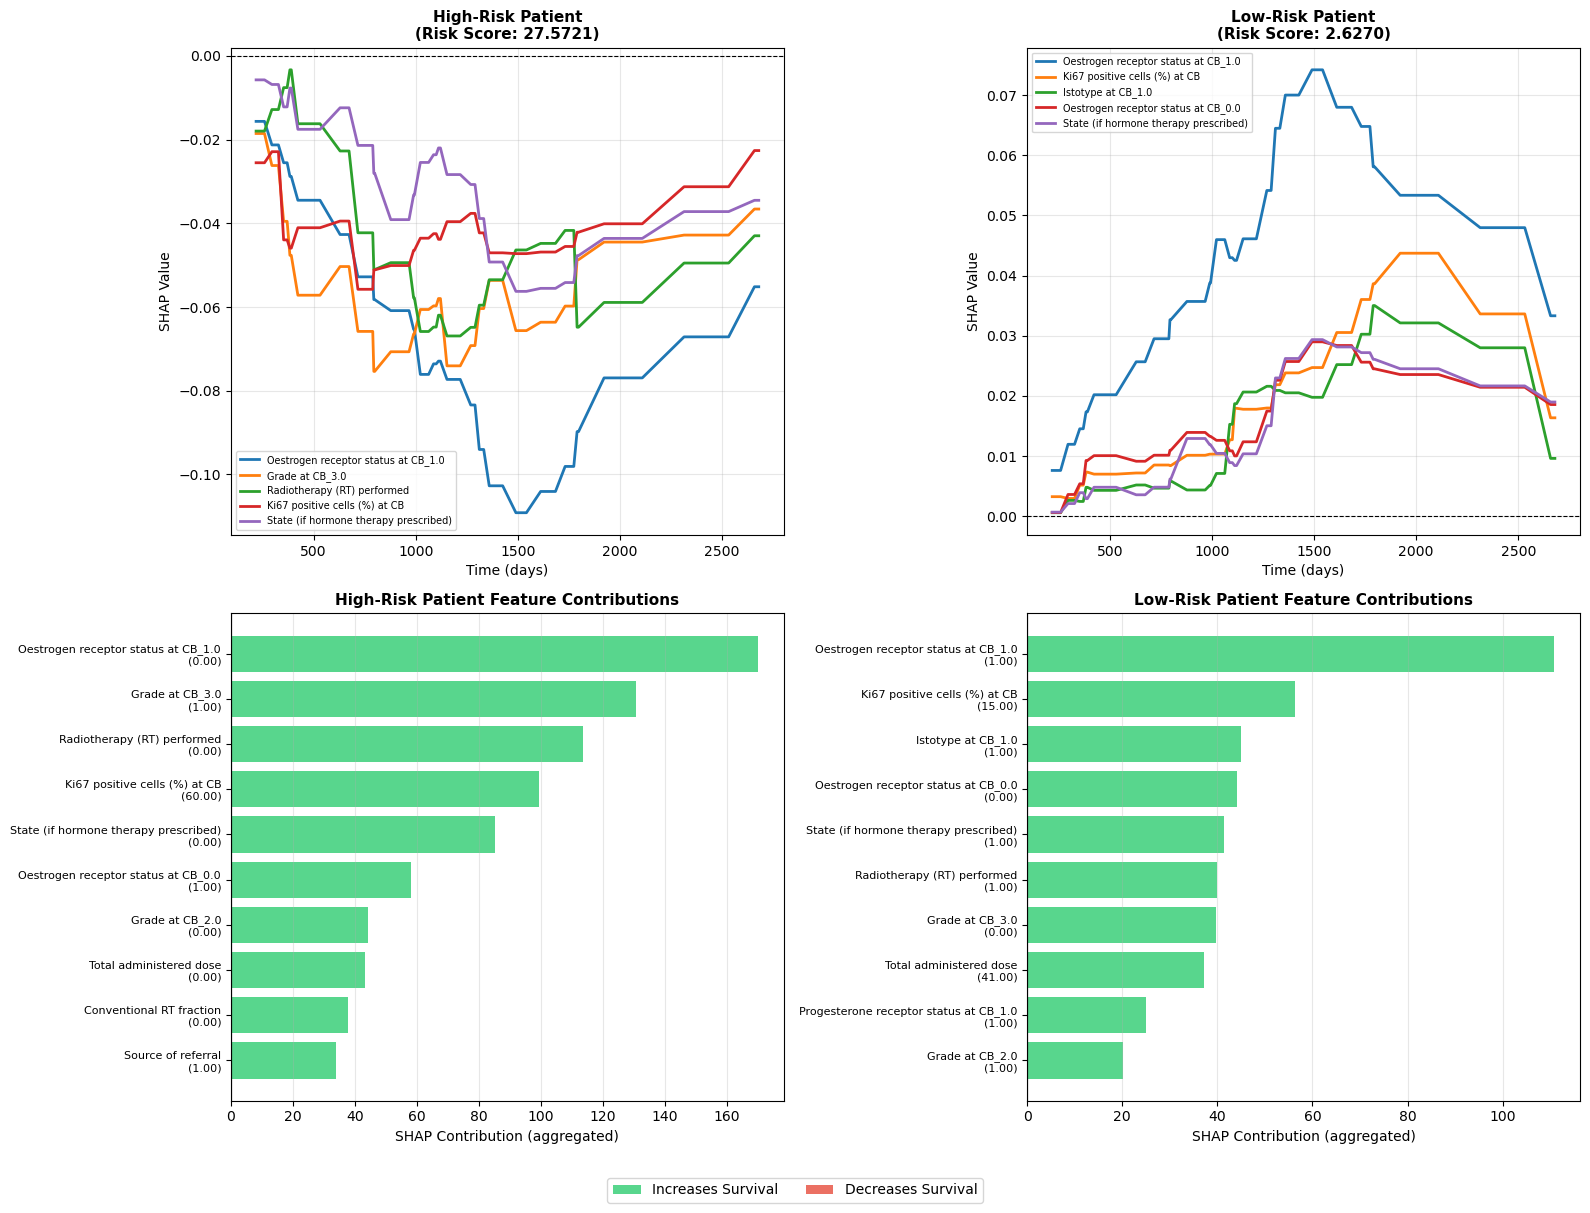

In [30]:
# ============================================
# PLOT INDIVIDUAL SURVSHAP - TIME-DEPENDENT CONTRIBUTIONS
# ============================================
# Visualize how each feature contributes to the survival prediction over time
# Note: With TreeSHAP, timestamps are based on model.unique_times_

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Get timestamps and results (TreeSHAP uses model.unique_times_ automatically)
timestamps_hr = survshap_high_risk.timestamps
timestamps_lr = survshap_low_risk.timestamps

# Get result DataFrames
result_hr = survshap_high_risk.result
result_lr = survshap_low_risk.result

# Filter for B=0 (averaged path) - TreeSHAP only has B=0
result_hr_avg = result_hr[result_hr['B'] == 0]
result_lr_avg = result_lr[result_lr['B'] == 0]

# Get time columns
time_cols_hr = [col for col in result_hr_avg.columns if col.startswith('t = ')]
time_cols_lr = [col for col in result_lr_avg.columns if col.startswith('t = ')]

# ---- Panel 1: High-risk patient - Top features over time ----
ax1 = axes[0, 0]
top_features_hr = high_risk_simplified['variable_name'].head(5).tolist()

for feature in top_features_hr:
    feature_row = result_hr_avg[result_hr_avg['variable_name'] == feature]
    if len(feature_row) > 0:
        shap_values = feature_row[time_cols_hr].values.flatten()
        # Handle dimension mismatch
        n_points = min(len(timestamps_hr), len(shap_values))
        ax1.plot(timestamps_hr[:n_points], shap_values[:n_points], linewidth=2, label=feature)

ax1.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax1.set_xlabel('Time (days)', fontsize=10)
ax1.set_ylabel('SHAP Value', fontsize=10)
ax1.set_title(f'High-Risk Patient\n(Risk Score: {risk_scores_background[high_risk_idx]:.4f})', fontsize=11, fontweight='bold')
ax1.legend(loc='best', fontsize=7)
ax1.grid(True, alpha=0.3)

# ---- Panel 2: Low-risk patient - Top features over time ----
ax2 = axes[0, 1]
top_features_lr = low_risk_simplified['variable_name'].head(5).tolist()

for feature in top_features_lr:
    feature_row = result_lr_avg[result_lr_avg['variable_name'] == feature]
    if len(feature_row) > 0:
        shap_values = feature_row[time_cols_lr].values.flatten()
        # Handle dimension mismatch
        n_points = min(len(timestamps_lr), len(shap_values))
        ax2.plot(timestamps_lr[:n_points], shap_values[:n_points], linewidth=2, label=feature)

ax2.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax2.set_xlabel('Time (days)', fontsize=10)
ax2.set_ylabel('SHAP Value', fontsize=10)
ax2.set_title(f'Low-Risk Patient\n(Risk Score: {risk_scores_background[low_risk_idx]:.4f})', fontsize=11, fontweight='bold')
ax2.legend(loc='best', fontsize=7)
ax2.grid(True, alpha=0.3)

# ---- Panel 3: High-risk patient - Waterfall plot (aggregated) ----
ax3 = axes[1, 0]
top_n = min(10, len(high_risk_simplified))
hr_plot_data = high_risk_simplified.head(top_n)

colors_hr = ['#e74c3c' if v < 0 else '#2ecc71' for v in hr_plot_data['aggregated_change']]
bars_hr = ax3.barh(range(top_n), hr_plot_data['aggregated_change'], color=colors_hr, alpha=0.8)
ax3.set_yticks(range(top_n))
ax3.set_yticklabels([f"{name}\n({val:.2f})" for name, val in zip(hr_plot_data['variable_name'], hr_plot_data['variable_value'])], fontsize=8)
ax3.invert_yaxis()
ax3.axvline(0, color='black', linewidth=0.8)
ax3.set_xlabel('SHAP Contribution (aggregated)', fontsize=10)
ax3.set_title('High-Risk Patient Feature Contributions', fontsize=11, fontweight='bold')
ax3.grid(True, alpha=0.3, axis='x')

# ---- Panel 4: Low-risk patient - Waterfall plot (aggregated) ----
ax4 = axes[1, 1]
top_n = min(10, len(low_risk_simplified))
lr_plot_data = low_risk_simplified.head(top_n)

colors_lr = ['#e74c3c' if v < 0 else '#2ecc71' for v in lr_plot_data['aggregated_change']]
bars_lr = ax4.barh(range(top_n), lr_plot_data['aggregated_change'], color=colors_lr, alpha=0.8)
ax4.set_yticks(range(top_n))
ax4.set_yticklabels([f"{name}\n({val:.2f})" for name, val in zip(lr_plot_data['variable_name'], lr_plot_data['variable_value'])], fontsize=8)
ax4.invert_yaxis()
ax4.axvline(0, color='black', linewidth=0.8)
ax4.set_xlabel('SHAP Contribution (aggregated)', fontsize=10)
ax4.set_title('Low-Risk Patient Feature Contributions', fontsize=11, fontweight='bold')
ax4.grid(True, alpha=0.3, axis='x')

# Add legend for colors
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2ecc71', alpha=0.8, label='Increases Survival'),
                   Patch(facecolor='#e74c3c', alpha=0.8, label='Decreases Survival')]
fig.legend(handles=legend_elements, loc='upper center', ncol=2, fontsize=10, bbox_to_anchor=(0.5, 0.02))

survshap_high_risk.result.to_csv('rsf_survshap_high_risk_full.csv', index=False)
survshap_low_risk.result.to_csv('rsf_survshap_low_risk_full.csv', index=False)

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig('rsf_survshap_individual.png', dpi=300, bbox_inches='tight')
print("✓ Individual SurvSHAP plot saved to 'rsf_survshap_individual.png'")
plt.show()

✓ Combined SHAP + Recalibrated Survival plot saved to 'rsf_survshap_with_survival_curves.png'


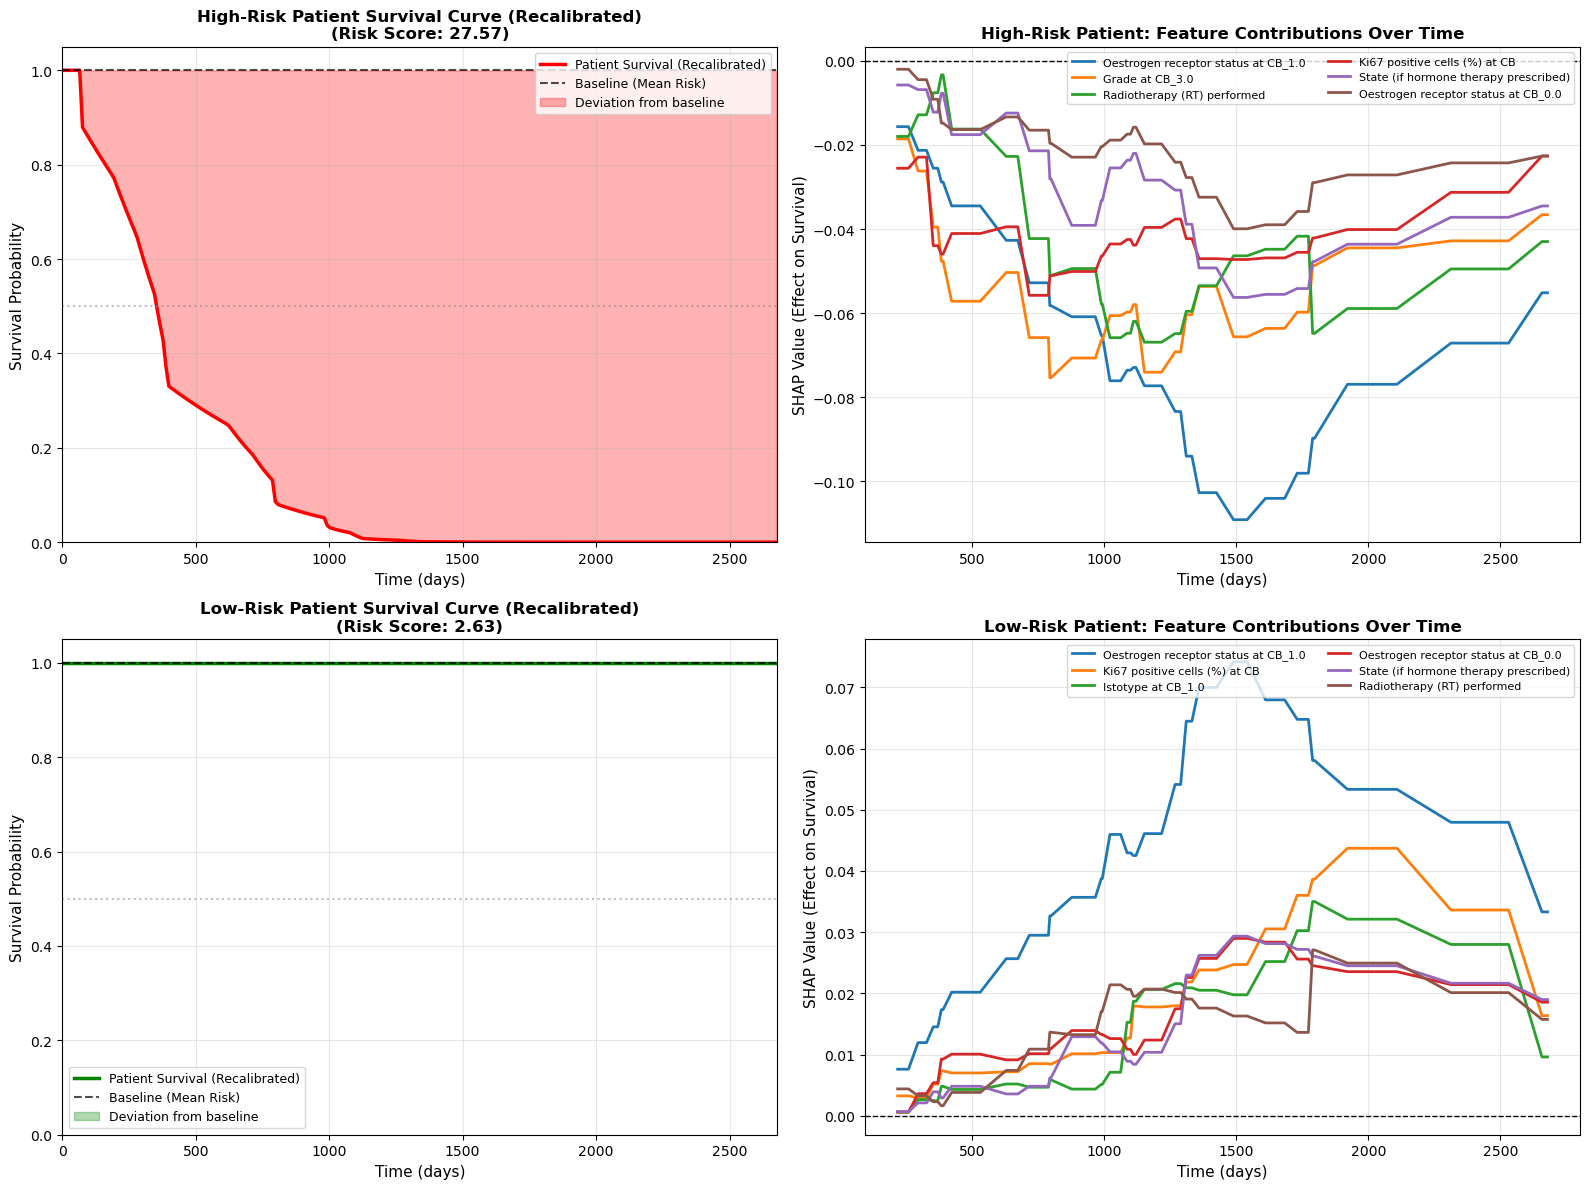

In [37]:
# ============================================
# COMBINED PLOT: SHAP CONTRIBUTIONS + RECALIBRATED SURVIVAL CURVE
# ============================================
# Shows how features contribute to survival over time alongside the RECALIBRATED survival curve
# Using Breslow baseline hazard estimated from full (non-subsampled) training pool

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Get risk scores for high and low risk patients
risk_hr = rsf_model_shap.predict(high_risk_obs)[0]
risk_lr = rsf_model_shap.predict(low_risk_obs)[0]

# Define time grid for recalibrated survival curves
time_grid = np.linspace(0, baseline_hazard_df_shap['timeline'].max(), 500)

# Compute RECALIBRATED survival functions using Breslow baseline hazard
surv_hr_recal = compute_recalibrated_survival(risk_hr, time_grid, baseline_hazard_df_shap)
surv_lr_recal = compute_recalibrated_survival(risk_lr, time_grid, baseline_hazard_df_shap)

# Get baseline (mean risk = 0) recalibrated survival function
baseline_surv_recal = compute_recalibrated_survival(0, time_grid, baseline_hazard_df_shap)

# Get SHAP results
result_hr = survshap_high_risk.result
result_lr = survshap_low_risk.result
result_hr_avg = result_hr[result_hr['B'] == 0]
result_lr_avg = result_lr[result_lr['B'] == 0]

timestamps_hr = survshap_high_risk.timestamps
timestamps_lr = survshap_low_risk.timestamps
time_cols_hr = [col for col in result_hr_avg.columns if col.startswith('t = ')]
time_cols_lr = [col for col in result_lr_avg.columns if col.startswith('t = ')]

# ============ HIGH-RISK PATIENT ============
# Panel 1: RECALIBRATED Survival Curve (clipped to SHAP timestamps)
ax1 = axes[0, 0]
# Clip survival curve to match SHAP timestamps
max_time_hr = timestamps_hr[-1]
mask_hr = time_grid <= max_time_hr

ax1.plot(time_grid[mask_hr], surv_hr_recal[mask_hr], 'r-', linewidth=2.5, label='Patient Survival (Recalibrated)')
ax1.plot(time_grid[mask_hr], baseline_surv_recal[mask_hr], 'k--', linewidth=1.5, alpha=0.7, label='Baseline (Mean Risk)')
ax1.fill_between(time_grid[mask_hr], surv_hr_recal[mask_hr], baseline_surv_recal[mask_hr], 
                  alpha=0.3, color='red', label='Deviation from baseline')
ax1.set_xlabel('Time (days)', fontsize=11)
ax1.set_ylabel('Survival Probability', fontsize=11)
ax1.set_title(f'High-Risk Patient Survival Curve (Recalibrated)\n(Risk Score: {risk_hr:.2f})', 
              fontsize=12, fontweight='bold')
ax1.legend(loc='upper right', fontsize=9)
ax1.set_ylim(0, 1.05)
ax1.set_xlim(0, max_time_hr)
ax1.grid(True, alpha=0.3)
ax1.axhline(0.5, color='gray', linestyle=':', alpha=0.5)

# Panel 2: SHAP over time (stacked area)
ax2 = axes[0, 1]
top_features_hr = high_risk_simplified['variable_name'].head(6).tolist()

# Create stacked area plot
positive_cumsum = np.zeros(len(timestamps_hr))
negative_cumsum = np.zeros(len(timestamps_hr))

colors_pos = plt.cm.Reds(np.linspace(0.3, 0.8, 6))
colors_neg = plt.cm.Blues(np.linspace(0.3, 0.8, 6))

for i, feature in enumerate(top_features_hr):
    feature_row = result_hr_avg[result_hr_avg['variable_name'] == feature]
    if len(feature_row) > 0:
        shap_values = feature_row[time_cols_hr].values.flatten()
        n_points = min(len(timestamps_hr), len(shap_values))
        shap_vals = shap_values[:n_points]
        times = timestamps_hr[:n_points]
        
        ax2.plot(times, shap_vals, linewidth=2, label=feature)

ax2.axhline(0, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel('Time (days)', fontsize=11)
ax2.set_ylabel('SHAP Value (Effect on Survival)', fontsize=11)
ax2.set_title('High-Risk Patient: Feature Contributions Over Time', fontsize=12, fontweight='bold')
ax2.legend(loc='best', fontsize=8, ncol=2)
ax2.grid(True, alpha=0.3)

# ============ LOW-RISK PATIENT ============
# Panel 3: RECALIBRATED Survival Curve (clipped to SHAP timestamps)
ax3 = axes[1, 0]
# Clip survival curve to match SHAP timestamps
max_time_lr = timestamps_lr[-1]
mask_lr = time_grid <= max_time_lr

ax3.plot(time_grid[mask_lr], surv_lr_recal[mask_lr], 'g-', linewidth=2.5, label='Patient Survival (Recalibrated)')
ax3.plot(time_grid[mask_lr], baseline_surv_recal[mask_lr], 'k--', linewidth=1.5, alpha=0.7, label='Baseline (Mean Risk)')
ax3.fill_between(time_grid[mask_lr], surv_lr_recal[mask_lr], baseline_surv_recal[mask_lr], 
                  alpha=0.3, color='green', label='Deviation from baseline')
ax3.set_xlabel('Time (days)', fontsize=11)
ax3.set_ylabel('Survival Probability', fontsize=11)
ax3.set_title(f'Low-Risk Patient Survival Curve (Recalibrated)\n(Risk Score: {risk_lr:.2f})', 
              fontsize=12, fontweight='bold')
ax3.legend(loc='lower left', fontsize=9)
ax3.set_ylim(0, 1.05)
ax3.set_xlim(0, max_time_lr)
ax3.grid(True, alpha=0.3)
ax3.axhline(0.5, color='gray', linestyle=':', alpha=0.5)

# Panel 4: SHAP over time
ax4 = axes[1, 1]
top_features_lr = low_risk_simplified['variable_name'].head(6).tolist()

for i, feature in enumerate(top_features_lr):
    feature_row = result_lr_avg[result_lr_avg['variable_name'] == feature]
    if len(feature_row) > 0:
        shap_values = feature_row[time_cols_lr].values.flatten()
        n_points = min(len(timestamps_lr), len(shap_values))
        ax4.plot(timestamps_lr[:n_points], shap_values[:n_points], linewidth=2, label=feature)

ax4.axhline(0, color='black', linestyle='--', linewidth=1)
ax4.set_xlabel('Time (days)', fontsize=11)
ax4.set_ylabel('SHAP Value (Effect on Survival)', fontsize=11)
ax4.set_title('Low-Risk Patient: Feature Contributions Over Time', fontsize=12, fontweight='bold')
ax4.legend(loc='best', fontsize=8, ncol=2)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('rsf_survshap_with_survival_curves.pdf', dpi=600, bbox_inches='tight')
print("✓ Combined SHAP + Recalibrated Survival plot saved to 'rsf_survshap_with_survival_curves.png'")
plt.show()

In [ ]:
# ============================================
# COMBINED PLOT: SHAP CONTRIBUTIONS + SURVIVAL CURVE
# ============================================
# Shows how features contribute to survival over time alongside the predicted survival curve

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Get the predicted survival functions for high and low risk patients
surv_func_hr = gbm_model_shap.predict_survival_function(high_risk_obs)[0]
surv_func_lr = gbm_model_shap.predict_survival_function(low_risk_obs)[0]

# Get baseline survival function (mean of background)
baseline_surv_funcs = gbm_model_shap.predict_survival_function(background_data)
baseline_surv = np.mean([f.y for f in baseline_surv_funcs], axis=0)
baseline_times = baseline_surv_funcs[0].x

# Get SHAP results
result_hr = survshap_high_risk.result
result_lr = survshap_low_risk.result
result_hr_avg = result_hr[result_hr['B'] == 0]
result_lr_avg = result_lr[result_lr['B'] == 0]

timestamps_hr = survshap_high_risk.timestamps
timestamps_lr = survshap_low_risk.timestamps
time_cols_hr = [col for col in result_hr_avg.columns if col.startswith('t = ')]
time_cols_lr = [col for col in result_lr_avg.columns if col.startswith('t = ')]

# ============ HIGH-RISK PATIENT ============
# Panel 1: Survival Curve
ax1 = axes[0, 0]
ax1.plot(surv_func_hr.x, surv_func_hr.y, 'r-', linewidth=2.5, label='Patient Survival')
ax1.plot(baseline_times, baseline_surv, 'k--', linewidth=1.5, alpha=0.7, label='Baseline (Mean)')
ax1.fill_between(surv_func_hr.x, surv_func_hr.y, baseline_surv[:len(surv_func_hr.y)], 
                  alpha=0.3, color='red', label='Deviation from baseline')
ax1.set_xlabel('Time (days)', fontsize=11)
ax1.set_ylabel('Survival Probability', fontsize=11)
ax1.set_title(f'High-Risk Patient Survival Curve\n(Risk Score: {risk_scores_background[high_risk_idx]:.2f})', 
              fontsize=12, fontweight='bold')
ax1.legend(loc='upper right', fontsize=9)
ax1.set_ylim(0, 1.05)
ax1.grid(True, alpha=0.3)
ax1.axhline(0.5, color='gray', linestyle=':', alpha=0.5)

# Panel 2: SHAP over time (stacked area)
ax2 = axes[0, 1]
top_features_hr = high_risk_simplified['variable_name'].head(6).tolist()

# Create stacked area plot
positive_cumsum = np.zeros(len(timestamps_hr))
negative_cumsum = np.zeros(len(timestamps_hr))

colors_pos = plt.cm.Reds(np.linspace(0.3, 0.8, 6))
colors_neg = plt.cm.Blues(np.linspace(0.3, 0.8, 6))

for i, feature in enumerate(top_features_hr):
    feature_row = result_hr_avg[result_hr_avg['variable_name'] == feature]
    if len(feature_row) > 0:
        shap_values = feature_row[time_cols_hr].values.flatten()
        n_points = min(len(timestamps_hr), len(shap_values))
        shap_vals = shap_values[:n_points]
        times = timestamps_hr[:n_points]
        
        ax2.plot(times, shap_vals, linewidth=2, label=feature)

ax2.axhline(0, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel('Time (days)', fontsize=11)
ax2.set_ylabel('SHAP Value (Effect on Survival)', fontsize=11)
ax2.set_title('High-Risk Patient: Feature Contributions Over Time', fontsize=12, fontweight='bold')
ax2.legend(loc='best', fontsize=8, ncol=2)
ax2.grid(True, alpha=0.3)

# Add annotation
ax2.annotate('← Decreases Survival', xy=(0.02, 0.02), xycoords='axes fraction', 
             fontsize=9, color='red', style='italic')
ax2.annotate('Increases Survival →', xy=(0.02, 0.95), xycoords='axes fraction', 
             fontsize=9, color='green', style='italic')

# ============ LOW-RISK PATIENT ============
# Panel 3: Survival Curve
ax3 = axes[1, 0]
ax3.plot(surv_func_lr.x, surv_func_lr.y, 'g-', linewidth=2.5, label='Patient Survival')
ax3.plot(baseline_times, baseline_surv, 'k--', linewidth=1.5, alpha=0.7, label='Baseline (Mean)')
ax3.fill_between(surv_func_lr.x, surv_func_lr.y, baseline_surv[:len(surv_func_lr.y)], 
                  alpha=0.3, color='green', label='Deviation from baseline')
ax3.set_xlabel('Time (days)', fontsize=11)
ax3.set_ylabel('Survival Probability', fontsize=11)
ax3.set_title(f'Low-Risk Patient Survival Curve\n(Risk Score: {risk_scores_background[low_risk_idx]:.2f})', 
              fontsize=12, fontweight='bold')
ax3.legend(loc='lower left', fontsize=9)
ax3.set_ylim(0, 1.05)
ax3.grid(True, alpha=0.3)
ax3.axhline(0.5, color='gray', linestyle=':', alpha=0.5)

# Panel 4: SHAP over time
ax4 = axes[1, 1]
top_features_lr = low_risk_simplified['variable_name'].head(6).tolist()

for i, feature in enumerate(top_features_lr):
    feature_row = result_lr_avg[result_lr_avg['variable_name'] == feature]
    if len(feature_row) > 0:
        shap_values = feature_row[time_cols_lr].values.flatten()
        n_points = min(len(timestamps_lr), len(shap_values))
        ax4.plot(timestamps_lr[:n_points], shap_values[:n_points], linewidth=2, label=feature)

ax4.axhline(0, color='black', linestyle='--', linewidth=1)
ax4.set_xlabel('Time (days)', fontsize=11)
ax4.set_ylabel('SHAP Value (Effect on Survival)', fontsize=11)
ax4.set_title('Low-Risk Patient: Feature Contributions Over Time', fontsize=12, fontweight='bold')
ax4.legend(loc='best', fontsize=8, ncol=2)
ax4.grid(True, alpha=0.3)

# Add annotation
ax4.annotate('← Decreases Survival', xy=(0.02, 0.02), xycoords='axes fraction', 
             fontsize=9, color='red', style='italic')
ax4.annotate('Increases Survival →', xy=(0.02, 0.95), xycoords='axes fraction', 
             fontsize=9, color='green', style='italic')

plt.tight_layout()
plt.savefig('gbm_survshap_with_survival_curves.png', dpi=300, bbox_inches='tight')
print("✓ Combined SHAP + Survival plot saved to 'gbm_survshap_with_survival_curves.png'")
plt.show()

SURVSHAP SUMMARY PLOT (BEESWARM-STYLE)
✓ SurvSHAP summary plot saved to 'rsf_survshap_summary.png'


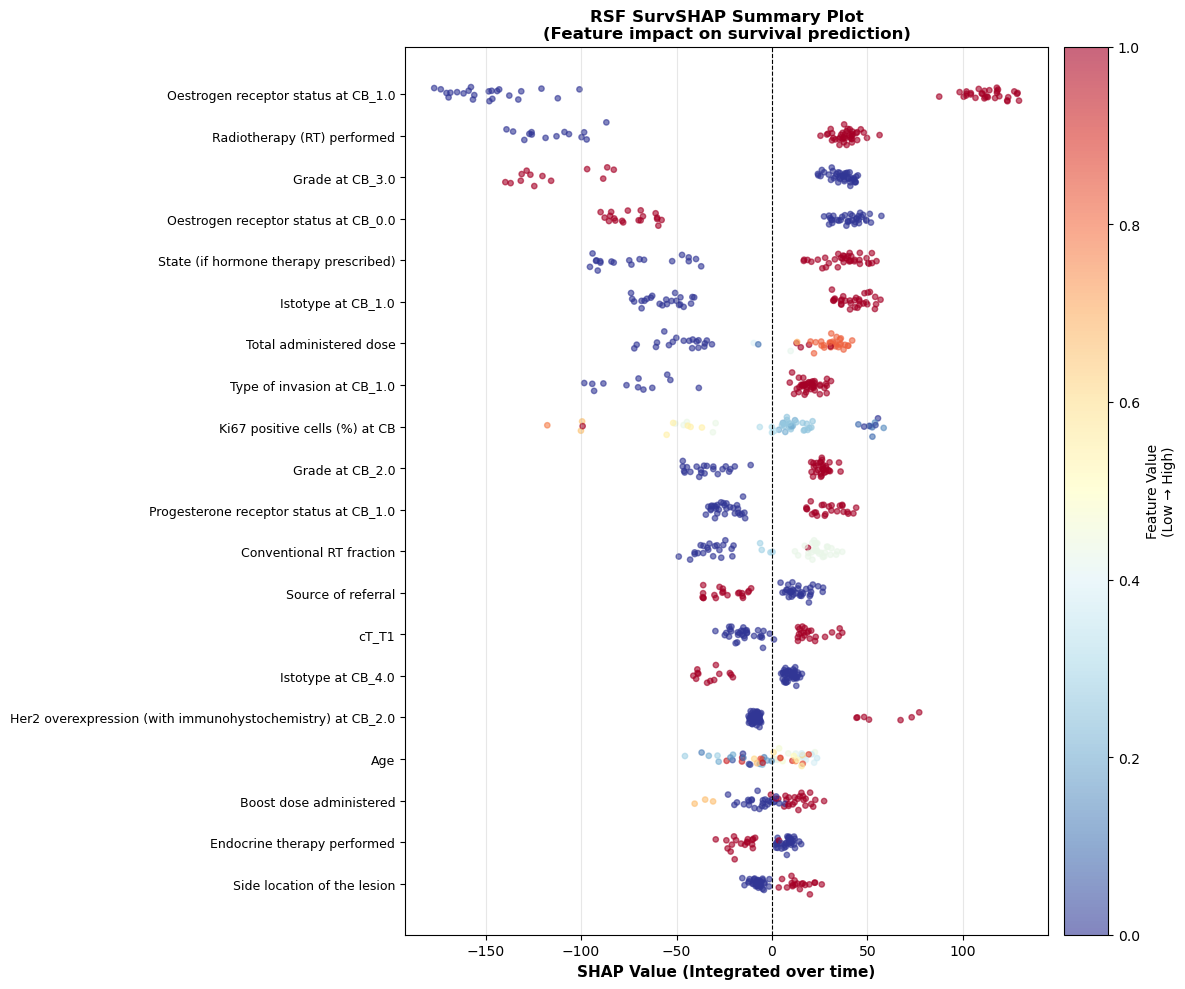

In [ ]:
# ============================================
# SURVSHAP BEESWARM / SUMMARY PLOT
# ============================================
# Create a summary plot showing SHAP value distributions for all features

print("="*70)
print("SURVSHAP SUMMARY PLOT (BEESWARM-STYLE)")
print("="*70)

# Extract individual SHAP values from global analysis
full_result = global_survshap.full_result
time_cols = [col for col in full_result.columns if col.startswith('t = ')]

# Calculate aggregated SHAP for each observation x feature
# Filter for B=0 (the averaged path)
result_b0 = full_result[full_result['B'] == 0].copy()

# Compute aggregated SHAP values using integral method
from scipy.integrate import trapezoid

feature_shap_values = {}
for feature in feature_columns:
    feature_data = result_b0[result_b0['variable_name'] == feature]
    if len(feature_data) > 0:
        shap_over_time = feature_data[time_cols].values
        # Integrate SHAP over time for each observation
        integrated_shap = [trapezoid(row, global_survshap.timestamps) for row in shap_over_time]
        feature_shap_values[feature] = integrated_shap

# Create DataFrame of SHAP values
shap_df = pd.DataFrame(feature_shap_values)

# Get feature importances (mean absolute SHAP)
feature_importance = shap_df.abs().mean().sort_values(ascending=False)

# Create summary plot
fig, ax = plt.subplots(figsize=(12, 10))

top_n = min(20, len(feature_importance))
top_features = feature_importance.head(top_n).index.tolist()

# For each feature, plot the distribution of SHAP values
for i, feature in enumerate(top_features):
    shap_vals = shap_df[feature].values
    feature_vals = background_data[feature].values
    
    # Normalize feature values for coloring
    feat_norm = (feature_vals - feature_vals.min()) / (feature_vals.max() - feature_vals.min() + 1e-10)
    
    # Add jitter for visibility
    y_jitter = np.random.normal(i, 0.1, size=len(shap_vals))
    
    scatter = ax.scatter(shap_vals, y_jitter, c=feat_norm, cmap='RdYlBu_r', 
                         alpha=0.6, s=15, vmin=0, vmax=1)

ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_features, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('SHAP Value (Integrated over time)', fontsize=11, fontweight='bold')
ax.set_title('RSF SurvSHAP Summary Plot\n(Feature impact on survival prediction)', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label('Feature Value\n(Low → High)', fontsize=10)

plt.tight_layout()
plt.savefig('rsf_survshap_summary.png', dpi=300, bbox_inches='tight')
print("✓ SurvSHAP summary plot saved to 'rsf_survshap_summary.png'")
plt.show()

In [ ]:
# ============================================
# COMPARE SURVSHAP VS PERMUTATION IMPORTANCE
# ============================================
# Compare feature rankings from SurvSHAP vs permutation importance

print("="*70)
print("COMPARISON: SurvSHAP vs Permutation Importance")
print("="*70)

# Get SurvSHAP rankings
survshap_importance = global_survshap.result[['variable_name', 'aggregated_change']].copy()
survshap_importance['survshap_rank'] = range(1, len(survshap_importance) + 1)
survshap_importance = survshap_importance.rename(columns={'aggregated_change': 'survshap_importance'})

# Get permutation importance rankings (from earlier analysis)
perm_importance_df = feature_df[['Feature', 'Importance']].copy()
perm_importance_df = perm_importance_df.rename(columns={'Feature': 'variable_name', 'Importance': 'perm_importance'})
perm_importance_df['perm_rank'] = range(1, len(perm_importance_df) + 1)

# Merge
comparison_df = survshap_importance.merge(perm_importance_df, on='variable_name', how='inner')
comparison_df['rank_diff'] = comparison_df['perm_rank'] - comparison_df['survshap_rank']

print(f"\nTop 15 Features - Comparison:")
print("-" * 90)
print(f"{'Feature':<35} {'SurvSHAP Rank':>12} {'Perm Rank':>10} {'Rank Δ':>8}")
print("-" * 90)

for idx, row in comparison_df.head(15).iterrows():
    print(f"{row['variable_name']:<35} {row['survshap_rank']:>12} {row['perm_rank']:>10} {row['rank_diff']:>+8}")

# Calculate Spearman correlation between rankings
from scipy.stats import spearmanr
rho, p_val = spearmanr(comparison_df['survshap_rank'], comparison_df['perm_rank'])

print(f"\n" + "="*70)
print(f"Spearman Rank Correlation: ρ = {rho:.4f} (p-value: {p_val:.4e})")
print("="*70)
print("Note: High correlation indicates consistency between SHAP and permutation importance")
print("      Differences occur because SurvSHAP considers time-dependence and interactions")

# Save comparison
comparison_df.to_csv('rsf_survshap_vs_permutation.csv', index=False)
print(f"\n✓ Comparison saved to 'rsf_survshap_vs_permutation.csv'")

COMPARISON: SurvSHAP vs Permutation Importance

Top 15 Features - Comparison:
------------------------------------------------------------------------------------------
Feature                             SurvSHAP Rank  Perm Rank   Rank Δ
------------------------------------------------------------------------------------------
Oestrogen receptor status at CB_1.0            1          1       +0
Radiotherapy (RT) performed                    2          3       +1
Grade at CB_3.0                                3         16      +13
Oestrogen receptor status at CB_0.0            4          4       +0
State (if hormone therapy prescribed)            5         30      +25
Istotype at CB_1.0                             6          2       -4
Total administered dose                        7         11       +4
Ki67 positive cells (%) at CB                  8         47      +39
Type of invasion at CB_1.0                     9          6       -3
Grade at CB_2.0                               1

In [ ]:
# ============================================
# SAVE ALL SURVSHAP RESULTS
# ============================================

print("="*70)
print("SAVING SURVSHAP RESULTS")
print("="*70)

# 1. Save global importance
global_results.to_csv('rsf_survshap_global_importance.csv', index=False)
print("✓ Global importance saved to 'rsf_survshap_global_importance.csv'")

# 2. Save full SHAP results (all observations, all time points)
full_result.to_csv('rsf_survshap_full_results.csv', index=False)
print("✓ Full results saved to 'rsf_survshap_full_results.csv'")

# 3. Save individual explanations for high and low risk patients
high_risk_simplified.to_csv('rsf_survshap_high_risk_patient.csv', index=False)
low_risk_simplified.to_csv('rsf_survshap_low_risk_patient.csv', index=False)
print("✓ Individual patient explanations saved")

# 4. Save SHAP values matrix (observations x features)
shap_df.to_csv('rsf_survshap_values_matrix.csv', index=False)
print("✓ SHAP values matrix saved to 'rsf_survshap_values_matrix.csv'")

# 5. Save timestamps
np.savetxt('rsf_survshap_timestamps.csv', global_survshap.timestamps, delimiter=',')
print("✓ Timestamps saved to 'rsf_survshap_timestamps.csv'")

# 6. Save to central features folder
global_results.to_csv('rsf_survshap_importance.csv', index=False)
print("✓ Also saved to 'rsf_survshap_importance.csv'")

print(f"\n" + "="*70)
print("SURVSHAP ANALYSIS COMPLETE")
print("="*70)
print(f"\nSummary of outputs:")
print(f"  - Global feature importance plot: 'rsf_survshap_global.png'")
print(f"  - Individual patient analysis plot: 'rsf_survshap_individual.png'")
print(f"  - Summary (beeswarm) plot: 'rsf_survshap_summary.png'")
print(f"  - CSV files with detailed results")
print(f"\nKey findings:")
print(f"  - Top 5 most important features (SurvSHAP):")
for i, row in global_results.head(5).iterrows():
    print(f"    {i+1}. {row['variable_name']}")

SAVING SURVSHAP RESULTS
✓ Global importance saved to 'rsf_survshap_global_importance.csv'
✓ Full results saved to 'rsf_survshap_full_results.csv'
✓ Individual patient explanations saved
✓ SHAP values matrix saved to 'rsf_survshap_values_matrix.csv'
✓ Timestamps saved to 'rsf_survshap_timestamps.csv'
✓ Also saved to 'rsf_survshap_importance.csv'

SURVSHAP ANALYSIS COMPLETE

Summary of outputs:
  - Global feature importance plot: 'rsf_survshap_global.png'
  - Individual patient analysis plot: 'rsf_survshap_individual.png'
  - Summary (beeswarm) plot: 'rsf_survshap_summary.png'
  - CSV files with detailed results

Key findings:
  - Top 5 most important features (SurvSHAP):
    28. Oestrogen receptor status at CB_1.0
    31. Radiotherapy (RT) performed
    14. Grade at CB_3.0
    27. Oestrogen receptor status at CB_0.0
    37. State (if hormone therapy prescribed)


# Patient Identification in Beeswarm Plots

This section adds patient identifiers to the SHAP analysis, allowing you to:
1. Save patient IDs alongside SHAP values
2. Create interactive plots to identify specific patients
3. Query which patients contribute to specific SHAP patterns

In [ ]:
# ============================================
# ADD PATIENT IDs TO SHAP RESULTS
# ============================================

print("="*70)
print("ADDING PATIENT IDENTIFIERS")
print("="*70)

# Extract patient IDs from the training pool used for SHAP
patient_ids = train_pool_dataset.iloc[background_idx]['PERSON_ID'].values

# Add patient IDs to the SHAP values dataframe
shap_df['PERSON_ID'] = patient_ids

# Save extended results with patient IDs
shap_df.to_csv('rsf_survshap_values_with_patient_ids.csv', index=False)
print(f"✓ SHAP values with patient IDs saved to 'rsf_survshap_values_with_patient_ids.csv'")

# Also add to full results if it contains individual observations
if 'observation' in full_result.columns:
    # Map observation index to patient ID
    patient_id_mapping = {i: pid for i, pid in enumerate(patient_ids)}
    full_result['PERSON_ID'] = full_result['observation'].map(patient_id_mapping)
    full_result.to_csv('rsf_survshap_full_results_with_ids.csv', index=False)
    print(f"✓ Full results with patient IDs saved to 'rsf_survshap_full_results_with_ids.csv'")

print(f"\nTotal patients in SHAP analysis: {len(patient_ids)}")
print(f"Sample patient IDs: {patient_ids[:5]}")

In [ ]:
# ============================================
# QUERY PATIENTS BY SHAP VALUES
# ============================================

print("\n" + "="*70)
print("PATIENT IDENTIFICATION EXAMPLES")
print("="*70)

# Example 1: Find patients with highest SHAP values for a specific feature
feature_of_interest = global_results.iloc[0]['variable_name']  # Top feature
feature_shap_col = f'shap_{feature_of_interest}'

if feature_shap_col in shap_df.columns:
    top_patients = shap_df.nlargest(10, feature_shap_col)[['PERSON_ID', feature_shap_col, feature_of_interest]]
    print(f"\nTop 10 patients with highest SHAP values for '{feature_of_interest}':")
    print(top_patients)
    
    bottom_patients = shap_df.nsmallest(10, feature_shap_col)[['PERSON_ID', feature_shap_col, feature_of_interest]]
    print(f"\nTop 10 patients with lowest SHAP values for '{feature_of_interest}':")
    print(bottom_patients)

# Example 2: Find patients in specific risk categories
print("\n" + "-"*70)
print("PATIENT RISK CATEGORIES")
print("-"*70)

# Calculate mean absolute SHAP (overall contribution to risk)
shap_columns = [col for col in shap_df.columns if col.startswith('shap_')]
shap_df['total_shap_magnitude'] = shap_df[shap_columns].abs().sum(axis=1)

# Categorize patients
high_risk_threshold = shap_df['total_shap_magnitude'].quantile(0.75)
low_risk_threshold = shap_df['total_shap_magnitude'].quantile(0.25)

high_risk_patients = shap_df[shap_df['total_shap_magnitude'] > high_risk_threshold]['PERSON_ID'].tolist()
low_risk_patients = shap_df[shap_df['total_shap_magnitude'] < low_risk_threshold]['PERSON_ID'].tolist()

print(f"High risk patients (top 25%): {len(high_risk_patients)} patients")
print(f"Sample IDs: {high_risk_patients[:5]}")
print(f"\nLow risk patients (bottom 25%): {len(low_risk_patients)} patients")
print(f"Sample IDs: {low_risk_patients[:5]}")

# Save risk categorization - use qcut for quantile-based binning (handles duplicates)
try:
    risk_category = pd.qcut(shap_df['total_shap_magnitude'], 
                            q=3, 
                            labels=['Low', 'Medium', 'High'],
                            duplicates='drop')
except ValueError:
    # If too few unique values, use simple thresholds
    conditions = [
        shap_df['total_shap_magnitude'] <= low_risk_threshold,
        shap_df['total_shap_magnitude'] <= high_risk_threshold,
        shap_df['total_shap_magnitude'] > high_risk_threshold
    ]
    risk_category = np.select(conditions, ['Low', 'Medium', 'High'], default='Medium')

risk_categories = pd.DataFrame({
    'PERSON_ID': shap_df['PERSON_ID'],
    'total_shap_magnitude': shap_df['total_shap_magnitude'],
    'risk_category': risk_category
})
risk_categories.to_csv('rsf_patient_risk_categories.csv', index=False)
print(f"\n✓ Patient risk categories saved to 'rsf_patient_risk_categories.csv'")

In [ ]:
# ============================================
# CREATE INTERACTIVE BEESWARM WITH PATIENT IDs
# ============================================

print("\n" + "="*70)
print("CREATING ANNOTATED BEESWARM PLOT")
print("="*70)

# Create an enhanced beeswarm plot for top feature with patient annotations
top_feature = global_results.iloc[0]['variable_name']
feature_shap_col = f'shap_{top_feature}'

if feature_shap_col in shap_df.columns:
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Get data for plotting
    shap_values_feat = shap_df[feature_shap_col].values
    feature_values = shap_df[top_feature].values
    
    # Normalize feature values for coloring
    feat_norm = (feature_values - feature_values.min()) / (feature_values.max() - feature_values.min() + 1e-10)
    
    # Create scatter plot
    scatter = ax.scatter(shap_values_feat, 
                        np.random.randn(len(shap_values_feat)) * 0.02,  # Small jitter on y-axis
                        c=feat_norm, 
                        cmap='coolwarm',
                        alpha=0.6,
                        s=50,
                        edgecolors='black',
                        linewidth=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label(f'{top_feature} value', rotation=270, labelpad=20)
    
    # Annotate extreme points with patient IDs
    n_annotate = 5  # Annotate 5 most extreme on each side
    
    # Most positive SHAP
    top_idx = np.argsort(shap_values_feat)[-n_annotate:]
    for idx in top_idx:
        ax.annotate(f"ID: {patient_ids[idx]}", 
                   (shap_values_feat[idx], np.random.randn() * 0.02),
                   xytext=(10, 5), textcoords='offset points',
                   fontsize=8, alpha=0.7,
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.3))
    
    # Most negative SHAP
    bottom_idx = np.argsort(shap_values_feat)[:n_annotate]
    for idx in bottom_idx:
        ax.annotate(f"ID: {patient_ids[idx]}", 
                   (shap_values_feat[idx], np.random.randn() * 0.02),
                   xytext=(-10, 5), textcoords='offset points',
                   fontsize=8, alpha=0.7, ha='right',
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='lightblue', alpha=0.3))
    
    ax.set_xlabel('SHAP Value (impact on survival prediction)', fontsize=12)
    ax.set_ylabel('')
    ax.set_yticks([])
    ax.axvline(x=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_title(f'SHAP Values for {top_feature}\n(Annotated with Patient IDs for extreme values)', 
                 fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='x')
    
    plt.tight_layout()
    plt.savefig('rsf_beeswarm_annotated.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Annotated beeswarm plot saved to 'rsf_beeswarm_annotated.png'")
    print(f"✓ Extreme patients (top/bottom {n_annotate}) are labeled with their PERSON_ID")

In [ ]:
# ============================================
# FUNCTION: QUERY SPECIFIC PATIENT
# ============================================

def get_patient_shap_profile(patient_id):
    """
    Get complete SHAP profile for a specific patient.
    
    Parameters:
    -----------
    patient_id : int or str
        The PERSON_ID to query
    
    Returns:
    --------
    DataFrame with patient's features, SHAP values, and contributions
    """
    if patient_id not in shap_df['PERSON_ID'].values:
        print(f"Patient {patient_id} not found in SHAP analysis")
        return None
    
    patient_row = shap_df[shap_df['PERSON_ID'] == patient_id].iloc[0]
    
    # Extract feature values and SHAP values
    profile = []
    for feat in global_results['variable_name']:
        shap_col = f'shap_{feat}'
        if shap_col in shap_df.columns and feat in shap_df.columns:
            profile.append({
                'feature': feat,
                'feature_value': patient_row[feat],
                'shap_value': patient_row[shap_col],
                'abs_shap': abs(patient_row[shap_col])
            })
    
    profile_df = pd.DataFrame(profile).sort_values('abs_shap', ascending=False)
    
    print(f"="*70)
    print(f"SHAP PROFILE FOR PATIENT {patient_id}")
    print(f"="*70)
    print(f"\nTop 10 most influential features:")
    print(profile_df.head(10).to_string(index=False))
    
    return profile_df

# Example usage
print("\n" + "="*70)
print("EXAMPLE: Patient SHAP Profile Query")
print("="*70)

example_patient = patient_ids[0]
patient_profile = get_patient_shap_profile(example_patient)

# Save as function for later use
print(f"\n✓ Function 'get_patient_shap_profile()' is now available")
print(f"  Usage: get_patient_shap_profile(PERSON_ID)")